In [ ]:
## Cell 0 — 환경 고정 (A100 1분 / L4 1분)
# 실행 후 "Restart session" 안내가 뜨면 재시작하고 Cell 1부터 진행
!pip -q install transformers==5.17.0 accelerate==1.14.0
import torch, transformers
print(torch.__version__, transformers.__version__, torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 8.5 MB/s eta 0:00:00
2.11.0+cu130 5.17.0 NVIDIA A100-SXM4-40GB


In [ ]:
## Cell 1 — 경로·결정성·데이터·프롬프트·채점기 (CPU, 1분)
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import json, re, ast, hashlib, string, unicodedata, time
from pathlib import Path
import numpy as np, pandas as pd, torch, transformers
from google.colab import drive
drive.mount('/content/drive')

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DS  = Path('/content/drive/MyDrive/Grad_share/data_share')
E15 = DS / 'E15'
OUT = DS / 'E17_ffn_patch'
(OUT / 'gen').mkdir(parents=True, exist_ok=True)

MAN = json.load(open(E15 / 'manifest.json'))
MODEL_ID, REV = 'meta-llama/Llama-3.1-8B-Instruct', MAN['model_rev']
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
ENV = dict(torch=torch.__version__, transformers=transformers.__version__,
           gpu=torch.cuda.get_device_name(0))
print(ENV, '| E15 기준:', MAN['transformers'], MAN['torch'])
assert transformers.__version__ == MAN['transformers'], 'transformers 버전 불일치 → Cell 0 재실행'

BEH = DS / 'P9' / 'hidden_v2' / 'p8s_behavior_v2.csv'
m = pd.read_csv(BEH)
m['rid'] = np.arange(len(m))
isCm = (m.ctx_label == 'C-').values
print(m.shape, '| behavior sha == manifest:', sha(BEH) == MAN['sha_behavior'])
print(m.ctx_label.value_counts().to_dict(), '| 질문 수', m.question.nunique())

# ── p8s-v2 프롬프트 (p8s_prompt.py와 같은 문자열. Cell 3에서 E15 출력과 대조해 검증)
SYSTEM_PROMPT = ("You are a question answering system. "
    "Answer the question based on the given context. "
    "Output the answer string itself and nothing else: no sentence, no explanation, "
    "no punctuation, no quotes. Keep it as short as possible (a name or a term).")
SYSTEM_PROMPT_CB = ("You are a question answering system. Answer from your own knowledge. "
    "Output the answer string itself and nothing else: no sentence, no explanation, "
    "no punctuation, no quotes. Keep it as short as possible (a name or a term).")
USER_TMPL    = 'Context: {ctx}\nQuestion: {q}\nAnswer:'
USER_TMPL_CB = 'Question: {q}\nAnswer:'
MAX_NEW_TOKENS = 192
msgs    = lambda q, c: [{'role': 'system', 'content': SYSTEM_PROMPT},
                        {'role': 'user', 'content': USER_TMPL.format(ctx=c, q=q)}]
msgs_cb = lambda q:    [{'role': 'system', 'content': SYSTEM_PROMPT_CB},
                        {'role': 'user', 'content': USER_TMPL_CB.format(q=q)}]

# ── 채점: trunc_fixed(이니셜·경칭 보호) + strict EM
PUNCT, ART = set(string.punctuation), {'a', 'an', 'the'}
def norm(s):
    s = unicodedata.normalize('NFKC', str(s)).lower()
    s = ''.join(ch for ch in s if ch not in PUNCT)
    return ' '.join(t for t in s.split() if t not in ART)
_SPLIT = re.compile(r'(?<![A-Z])(?<!\bDr)(?<!\bMr)(?<!\bMs)(?<!\bSt)(?<!\bJr)(?<!\bSr)(?<!\bMrs)\.\s+')
def trunc_fixed(raw):
    s = str(raw).strip().split('\n')[0].strip()
    s = re.sub(r'^(answer|the answer is)\s*:?\s*', '', s, flags=re.I)
    s = _SPLIT.split(s)[0].strip().strip('"\'')
    return re.sub(r'[.,;:\s]+$', '', s).strip()

def parse_gold(x):
    s = str(x)
    for f in (ast.literal_eval, json.loads):
        try:
            v = f(s)
            if isinstance(v, (list, tuple)): return [str(t) for t in v]
        except Exception:
            pass
    return [t.strip() for t in s.split('|') if t.strip()]
GL   = [parse_gold(x) for x in m.gold_list]
SURF = m.answer_surface.fillna('').astype(str).tolist()
em_of = lambda p, g: int(norm(p) in {norm(x) for x in g})
fc_of = lambda p, s: int(bool(norm(s)) and norm(p) == norm(s))

def score(raws, rids):
    P = [trunc_fixed(r) for r in raws]
    return pd.DataFrame({'rid': rids, 'pred': P,
                         'em': [em_of(p, GL[i]) for p, i in zip(P, rids)],
                         'fc': [fc_of(p, SURF[i]) for p, i in zip(P, rids)]})

print('gold_list 원문:', str(m.gold_list.iloc[0])[:100])
print('파싱 결과   :', GL[0][:6], '| 빈 리스트 행:', sum(len(g) == 0 for g in GL))
print('trunc 점검  :', [trunc_fixed(x) for x in ['Dr. Dre', 'T.S. Eliot', 'Ronald D. Moore', 'Paris. It is']])

Mounted at /content/drive
{'torch': '2.11.0+cu130', 'transformers': '5.17.0', 'gpu': 'NVIDIA A100-SXM4-40GB'} | E15 기준: 5.17.0 2.11.0+cu128
(1224, 23) | behavior sha == manifest: False
{'C+': 612, 'C-': 612} | 질문 수 612
gold_list 원문: ['Bollywood', 'HFI', 'HLFI', 'Hindi language film industry', 'Hindi Cinema', 'HIFI']
파싱 결과   : ['Bollywood', 'HFI', 'HLFI', 'Hindi language film industry', 'Hindi Cinema', 'HIFI'] | 빈 리스트 행: 0
trunc 점검  : ['Dr. Dre', 'T.S. Eliot', 'Ronald D. Moore', 'Paris']


In [ ]:
## Cell 2 — 행 순서 대조, 모델 로드, 프롬프트 토큰화, suffix 정렬 확인 (A100 2분 / L4 3분)
# ── ① 행 순서 대조 (E15 folds.parquet 기준)
print('behavior 열:', m.columns.tolist())
FO = pd.read_parquet(E15 / 'folds.parquet')
print('folds 열:', FO.columns.tolist(), FO.shape)
if 'rid' in FO: FO = FO.sort_values('rid').reset_index(drop=True)
if len(FO) == len(m) and 'question' in FO:
    print('질문 순서 일치(1224행):', (FO.question.values == m.question.values).all())
    if 'ctx_label' in FO:
        print('C 라벨 순서 일치:', (FO.ctx_label.values == m.ctx_label.values).all())
elif 'question' in FO:
    print('folds는 질문 단위 → 질문 집합 일치:', set(FO.question) == set(m.question))

# ── ② 모델·토크나이저
from huggingface_hub import login
try:
    from google.colab import userdata
    login(userdata.get('HF_TOKEN'))
except Exception:
    login()
from transformers import AutoTokenizer, AutoModelForCausalLM
TOK = AutoTokenizer.from_pretrained(MODEL_ID, revision=REV)
TOK.padding_side = 'left'
if TOK.pad_token is None:
    TOK.pad_token = TOK.eos_token
MODEL = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REV, dtype=torch.bfloat16, attn_implementation='sdpa').cuda().eval()
LAYERS = MODEL.model.layers
EOS = set(np.atleast_1d(MODEL.generation_config.eos_token_id).tolist()) | {TOK.pad_token_id}
print('layers', len(LAYERS), '| eos', EOS, '| pad', TOK.pad_token, TOK.pad_token_id)

# ── ③ 프롬프트 → 토큰 (문자열에 BOS 포함되므로 add_special_tokens=False)
enc = lambda s: TOK(s, add_special_tokens=False)['input_ids']
m['prompt']    = [TOK.apply_chat_template(msgs(r.question, r.ctx_text), tokenize=False,
                                          add_generation_prompt=True) for r in m.itertuples()]
m['prompt_cb'] = [TOK.apply_chat_template(msgs_cb(q), tokenize=False,
                                          add_generation_prompt=True) for q in m.question]
IDS    = [enc(p) for p in m.prompt]
IDS_CB = [enc(p) for p in m.prompt_cb]
assert all(i[0] == TOK.bos_token_id and i[1] != TOK.bos_token_id for i in IDS), 'BOS 중복/누락'

# ── ④ 공통 suffix: 문맥 프롬프트와 CB 프롬프트의 끝에서부터 같은 토큰 수
def common_suffix(a, b):
    n = 0
    while n < min(len(a), len(b)) and a[-1 - n] == b[-1 - n]:
        n += 1
    return n
m['n_tok']    = [len(i) for i in IDS]
m['n_tok_cb'] = [len(i) for i in IDS_CB]
m['L_suf']    = [common_suffix(a, b) for a, b in zip(IDS, IDS_CB)]
has_q = np.array([r.question in TOK.decode(IDS[r.rid][-r.L_suf:]) for r in m.itertuples()])
print('n_tok 중앙값/최대:', int(m.n_tok.median()), m.n_tok.max(),
      '| CB 중앙값:', int(m.n_tok_cb.median()))
print('L_suf min/중앙값/max:', m.L_suf.min(), int(m.L_suf.median()), m.L_suf.max(),
      '| 질문 전체 포함 비율:', has_q.mean())
print('suffix 예시:', repr(TOK.decode(IDS[0][-m.L_suf[0]:])))
print('suffix 직전 토큰 (문맥/CB):', repr(TOK.decode(IDS[0][-m.L_suf[0] - 1])),
      '/', repr(TOK.decode(IDS_CB[0][-m.L_suf[0] - 1])))
assert has_q.all(), 'suffix에 질문이 다 안 들어간 행이 있음 → 출력 공유'

behavior 열: ['question', 'gold', 'prop', 'kside', 'knows', 'A_cb', 'ctx_id', 'ctx_title', 's_wiki_title', 'orig_gold', 'ctx_label', 'ctx_text', 'answer_surface', 'ans_start', 'ans_end', 'wrong_answer', 'gold_list', 'kside_k', 'kside_new', 'kside_corr', 'k_agree', 'cell_k', 'rid']
folds 열: ['row', 'question', 'fold', 'inner0', 'inner1', 'inner2', 'inner3', 'inner4'] (1224, 8)
질문 순서 일치(1224행): True


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

layers 32 | eos {128008, 128001, 128009} | pad <|eot_id|> 128009


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


n_tok 중앙값/최대: 238 377 | CB 중앙값: 95
L_suf min/중앙값/max: 14 18 30 | 질문 전체 포함 비율: 1.0
suffix 예시: 'Question: What genre is Kanoon?\nAnswer:<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n'
suffix 직전 토큰 (문맥/CB): '\n' / '\n\n'


In [ ]:
## Cell 3 — 생성 함수 + E15 base 재현 관문 (A100 1.5분 / L4 4분)
DECODE_KW = dict(skip_special_tokens=True, clean_up_tokenization_spaces=False)

@torch.inference_mode()
def generate(id_lists, max_new=MAX_NEW_TOKENS):
    b = TOK.pad({'input_ids': id_lists}, padding=True, return_tensors='pt')
    ids, am = b['input_ids'].cuda(), b['attention_mask'].cuda()
    out = MODEL.generate(input_ids=ids, attention_mask=am, max_new_tokens=max_new,
                         do_sample=False, temperature=None, top_p=None, top_k=None,
                         pad_token_id=TOK.pad_token_id)
    g = out[:, ids.shape[1]:].cpu().numpy()
    n = [next((j for j, t in enumerate(row) if t in EOS), len(row)) for row in g]
    raws = [TOK.decode(row[:k].tolist(), **DECODE_KW) for row, k in zip(g, n)]
    return raws, n

# ── E15 배치 구성 로드
BJ = json.load(open(E15 / 'batches_bs16_tierand.json'))
print('batches 타입:', type(BJ).__name__, (list(BJ)[:5] if isinstance(BJ, dict) else len(BJ)))
BATCH_E15 = BJ.get('batches', next(iter(BJ.values()))) if isinstance(BJ, dict) else BJ
assert all(isinstance(b, list) for b in BATCH_E15), '배치 구조 확인 필요 → 출력 공유'
assert sorted(sum(BATCH_E15, [])) == list(range(len(m))), '배치가 1224행을 정확히 덮지 않음'
print('배치 수', len(BATCH_E15), '| 크기', sorted({len(b) for b in BATCH_E15}))

# ── E15 저장본 + 채점기 대조
REF = pd.read_parquet(E15 / 'gen_base_tierand.parquet')
print('E15 gen 열:', REF.columns.tolist())
REF = REF.sort_values('row').reset_index(drop=True)
assert (REF.row.values == np.arange(len(m))).all()
s_ref = score(REF.raw.tolist(), REF.row.tolist())
if 'em' in REF:
    bad = s_ref.em.values != REF.em.values
    print('채점기 em 불일치 행:', int(bad.sum()))
    if bad.any():
        print(pd.DataFrame({'raw': REF.raw[bad], 'pred': s_ref.pred[bad],
                            'e15_em': REF.em[bad], 'ours': s_ref.em[bad]}).head(8).to_string())

# ── base 재생성 (체크포인트)
p_base = OUT / 'gen' / 'base_e15batch.parquet'
if p_base.exists():
    B0 = pd.read_parquet(p_base)
else:
    t0, rows = time.time(), []
    for b in BATCH_E15:
        raws, n = generate([IDS[i] for i in b])
        rows += [dict(row=i, raw=r, n_gen=k) for i, r, k in zip(b, raws, n)]
    B0 = pd.DataFrame(rows).sort_values('row').reset_index(drop=True)
    B0.to_parquet(p_base)
    print(f'생성 {time.time() - t0:.0f}s')

match = B0.raw.values == REF.raw.values
print(f'E15 base 문자열 일치 {match.sum()}/{len(m)} | C− {match[isCm].sum()}/612 '
      f'| hit_limit {np.mean(B0.n_gen >= MAX_NEW_TOKENS):.3f}')
if not match.all():
    print(pd.DataFrame({'row': B0.row[~match], 'ours': B0.raw[~match],
                        'e15': REF.raw[~match]}).head(10).to_string())
s0 = score(B0.raw.tolist(), B0.row.tolist())
print(f'base EM  C− {s0.em[isCm].mean():.4f} ({s0.em[isCm].sum()}) '
      f'| C+ {s0.em[~isCm].mean():.4f} ({s0.em[~isCm].sum()}) '
      f'| C− follows_ctx {s0.fc[isCm].mean():.4f}')

batches 타입: list 77
배치 수 77 | 크기 [8, 16]
E15 gen 열: ['row', 'raw', 'n_tok', 'hit_limit', 'em', 'fc', 'em_old', 'fc_old']
채점기 em 불일치 행: 0
생성 51s
E15 base 문자열 일치 1224/1224 | C− 612/612 | hit_limit 0.000
base EM  C− 0.2598 (159) | C+ 0.8007 (490) | C− follows_ctx 0.4722


In [ ]:
## Cell 4 — closed-book 답 → K_strict, follows_cb 기준 (A100 30초 / L4 1분)
# ── (Cell 3 보완) follows_ctx 채점기 대조
bad = s_ref.fc.values != REF.fc.values
print('채점기 fc 불일치 행:', int(bad.sum()))
if bad.any():
    print(pd.DataFrame({'pred': s_ref.pred[bad], 'surf': np.array(SURF)[bad],
                        'e15': REF.fc[bad], 'ours': s_ref.fc[bad]}).head(8).to_string())

# ── CB 생성: C− 행 612개(질문당 1행)만. 길이순 정렬 + bs32
RID_CM = m.rid.values[isCm]
p_cb = OUT / 'gen' / 'cb16.parquet'
if p_cb.exists():
    CB = pd.read_parquet(p_cb)
else:
    t0, rows = time.time(), []
    order = RID_CM[np.argsort([len(IDS_CB[i]) for i in RID_CM], kind='stable')]
    for s in range(0, len(order), 32):
        rr = order[s:s + 32]
        raws, n = generate([IDS_CB[i] for i in rr], max_new=16)
        rows += [dict(rid=i, cb_raw=r, cb_n=k) for i, r, k in zip(rr, raws, n)]
    CB = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    CB.to_parquet(p_cb)
    print(f'생성 {time.time() - t0:.0f}s')

CB['cb_pred'] = CB.cb_raw.map(trunc_fixed)
CB['K'] = [em_of(p, GL[i]) for p, i in zip(CB.cb_pred, CB.rid)]
CBP = dict(zip(CB.rid, CB.cb_pred))
KS  = dict(zip(CB.rid, CB.K))
print(f'CB EM {CB.K.mean():.4f} | K_strict K+ {CB.K.sum()} | 16토큰 도달 {(CB.cb_n >= 16).sum()}행')

# ── E15 CB(cb_v4)와 대조 — 열 이름 확인 후 질문 기준 정렬
CV = pd.read_parquet(E15 / 'cb_v4.parquet')
print('cb_v4 열:', CV.columns.tolist(), CV.shape)
raw_col = next((c for c in CV.columns if 'raw' in c or 'greedy' in c), None)
if raw_col and 'question' in CV:
    ref_cb = dict(zip(CV.question, CV[raw_col].map(trunc_fixed)))
    same = np.mean([norm(CBP[r]) == norm(ref_cb.get(m.question[r], '')) for r in RID_CM])
    print(f'cb_v4[{raw_col}]와 정규화 답 일치율: {same:.3f}')

# ── base C− 셀 분해 (K_strict 기준)
Kp = np.array([KS[r] for r in RID_CM]).astype(bool)
e0 = s0.set_index('rid').loc[RID_CM]
print(f'base C− EM: K+C− {e0.em.values[Kp].mean():.3f} (n={Kp.sum()}) '
      f'| K−C− {e0.em.values[~Kp].mean():.3f} (n={(~Kp).sum()})')
print(f'base C− follows_ctx: K+C− {e0.fc.values[Kp].mean():.3f} | K−C− {e0.fc.values[~Kp].mean():.3f}')

채점기 fc 불일치 행: 62
                         pred               surf  e15  ours
36             Fantasy writer            fantasy    1     0
65        Pop Rock Jazz Swing               jazz    1     0
67            Fire engine red                red    1     0
105  Casual puzzle video game  puzzle video game    1     0
137                Edo Castle                Edo    1     0
139     Television journalist         journalist    1     0
145             King George V           George V    1     0
148   Amy Tan and Ronald Bass            Amy Tan    1     0
생성 13s
CB EM 0.5163 | K_strict K+ 316 | 16토큰 도달 2행
cb_v4 열: ['question', 'cb_raw'] (612, 2)
cb_v4[cb_raw]와 정규화 답 일치율: 0.992
base C− EM: K+C− 0.446 (n=316) | K−C− 0.061 (n=296)
base C− follows_ctx: K+C− 0.389 | K−C− 0.561


In [ ]:
B0, REF = B0.rename(columns={'row': 'rid'}), REF.rename(columns={'row': 'rid'})

## Cell 5 — fc 정의 수정, 패치 훅, 훅 단위 검증, 실험 배치, 사전등록 (A100 10초 / L4 20초)
# ── ① follows_ctx = 문맥 답 포함 여부 (E15·p8s_prompt.score_row 정의)
fc_of = lambda p, s: int(bool(s) and norm(s) in norm(p))
s_ref = score(REF.raw.tolist(), REF.rid.tolist())
print('채점기 fc 불일치 행(수정 후):', int((s_ref.fc.values != REF.fc.values).sum()))
s0 = score(B0.raw.tolist(), B0.rid.tolist())
e0 = s0.set_index('rid').loc[RID_CM]
print(f'base C− follows_ctx {e0.fc.mean():.4f} | K+C− {e0.fc.values[Kp].mean():.3f} '
      f'| K−C− {e0.fc.values[~Kp].mean():.3f}')

# ── ② 패치 훅: prefill에서만, 문맥 행 a의 마지막 L토큰을 소스 행 b 값으로 덮어씀
WINDOWS = {'L08-12': list(range(8, 13)), 'L14-18': list(range(14, 19)), 'L20-24': list(range(20, 25))}
COMPS = ('resid', 'attn', 'mlp')
PATCH = {'on': False, 'pairs': []}

def _patch(t):
    if not PATCH['on'] or t.shape[1] == 1:      # decode 스텝(길이 1)은 통과
        return
    for a, b, L in PATCH['pairs']:
        t[a, -L:] = t[b, -L:]                   # left padding → 끝 정렬

def hook_resid(mod, inp, out): _patch(out[0] if isinstance(out, tuple) else out); return out
def hook_attn(mod, inp, out):  _patch(out[0]); return out
def hook_mlp(mod, inp, out):   _patch(out); return out

def register(comp, layers):
    tgt = {'resid': lambda l: (LAYERS[l], hook_resid),
           'attn':  lambda l: (LAYERS[l].self_attn, hook_attn),
           'mlp':   lambda l: (LAYERS[l].mlp, hook_mlp)}[comp]
    return [mod.register_forward_hook(h) for mod, h in (tgt(l) for l in layers)]

def make_pairs(b, mis=False):
    n = len(b)
    if not mis:
        return [(a, n + a, int(m.L_suf[b[a]])) for a in range(n)]
    return [(a, n + (a + 1) % n, int(min(m.L_suf[b[a]], m.L_suf[b[(a + 1) % n]]))) for a in range(n)]

# ── ③ 실험 배치: C− 612행, (문맥 길이, seed0 무작위) 정렬, 16질문씩. 배치 = 문맥 16 + CB 16
rng = np.random.RandomState(0)
cm = m.loc[isCm, ['rid', 'n_tok']].copy()
cm['tie'] = rng.rand(len(cm))
cm = cm.sort_values(['n_tok', 'tie'])
BATCHES = [cm.rid.values[i:i + 16].tolist() for i in range(0, len(cm), 16)]
print('실험 배치', len(BATCHES), '개 | 크기', sorted({len(b) for b in BATCHES}))

# ── ④ 훅 단위 검증 (첫 배치, prefill forward 1회씩)
@torch.inference_mode()
def last_logits(b, comp=None, layers=(), mis=False):
    bt = TOK.pad({'input_ids': [IDS[r] for r in b] + [IDS_CB[r] for r in b]},
                 padding=True, return_tensors='pt')
    hs = register(comp, layers) if comp else []
    PATCH.update(on=bool(comp), pairs=make_pairs(b, mis))
    try:
        lg = MODEL(input_ids=bt['input_ids'].cuda(),
                   attention_mask=bt['attention_mask'].cuda()).logits[:, -1].float()
    finally:
        PATCH['on'] = False
        for h in hs: h.remove()
    return lg

b = BATCHES[0]; n = len(b)
lg0  = last_logits(b)
lg31 = last_logits(b, 'resid', [31])
lgm  = last_logits(b, 'mlp', WINDOWS['L14-18'])
print('resid L31 패치 후 문맥행 top1 == CB행 top1:',
      (lg31[:n].argmax(-1) == lg0[n:].argmax(-1)).float().mean().item(), '(기대 1.0)')
print('패치 전 문맥행 top1 == CB행 top1:',
      (lg0[:n].argmax(-1) == lg0[n:].argmax(-1)).float().mean().item())
print('mlp L14-18 패치 후 문맥행 logit 변화 max|Δ|:', (lgm[:n] - lg0[:n]).abs().max().item(), '(기대 > 0)')
print('mlp 패치 후 CB행 불변 max|Δ|:', (lgm[n:] - lg0[n:]).abs().max().item(), '(기대 0)')

# ── ⑤ 조건 목록 + 사전등록
COND = {'base_pair': (None, [], False)}
for w, ls in WINDOWS.items():
    for c in COMPS:
        COND[f'{c}_{w}'] = (c, ls, False)
for c in COMPS:
    COND[f'{c}_L14-18_mis'] = (c, WINDOWS['L14-18'], True)

PREREG = dict(
    exp='E17-1 activation patching: 문맥(C−) 행의 공통 suffix에 closed-book 런의 성분을 덮어씀 (oracle C, 탐색적 경로 진단)',
    date='2026-10-05', rows='C− 612행(질문당 1행)', source='SYSTEM_PROMPT_CB 프롬프트, 같은 배치 동시 forward',
    positions='공통 suffix 토큰(질문+템플릿 끝), prefill만, decode 개입 없음',
    conditions=list(COND), baseline='base_pair (같은 32시퀀스 배치, 패치 없음)',
    primary='창 L14-18: R_EM = ΔEM(mlp)/ΔEM(resid), ΔEM은 base_pair 대비 질문 단위 paired',
    rules={'전제': 'ΔEM(resid_L14-18) 95% CI 하한 > 0, 아니면 판정 보류',
           'FFN 단독 경로 기각': 'R_EM 95% CI 상한 < 0.3',
           '2단계 진행': 'R_EM 95% CI 하한 > 0.5 그리고 ΔEM(mlp_L14-18) − ΔEM(mlp_L14-18_mis) 95% CI 하한 > 0',
           '그 외': '판정 보류'},
    secondary=['ΔFC(문맥 답 포함), ΔFCB(CB답과 일치)', 'K_strict(K+ 316) 분해',
               '창 L08-12·L20-24 (탐색적)', 'attn 비율'],
    bootstrap=dict(B=2000, seed=0, unit='질문'),
    scorer='trunc_fixed + strict EM, fc=문맥 답 포함 (E15와 채점 0 불일치)',
    env=ENV, model_rev=REV,
    batches_sha=hashlib.sha256(json.dumps([list(map(int, b)) for b in BATCHES]).encode()).hexdigest()[:12])
p_pre = OUT / 'prereg_e17_1.json'
if not p_pre.exists():
    p_pre.write_text(json.dumps(PREREG, ensure_ascii=False, indent=1))
print('조건', len(COND), '개 | prereg sha', sha(p_pre)[:12])

채점기 fc 불일치 행(수정 후): 0
base C− follows_ctx 0.5147 | K+C− 0.402 | K−C− 0.635
실험 배치 39 개 | 크기 [4, 16]
resid L31 패치 후 문맥행 top1 == CB행 top1: 1.0 (기대 1.0)
패치 전 문맥행 top1 == CB행 top1: 0.375
mlp L14-18 패치 후 문맥행 logit 변화 max|Δ|: 11.625 (기대 > 0)
mlp 패치 후 CB행 불변 max|Δ|: 0.0 (기대 0)
조건 13 개 | prereg sha f30f59bc3cff


In [ ]:
## Cell 6 — 13조건 실행 (조건당 A100 ~1분 / L4 ~2.5분 → 전체 A100 ~13분 / L4 ~33분)
def run(name):
    p = OUT / 'gen' / f'{name}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    comp, layers, mis = COND[name]
    hs = register(comp, layers) if comp else []
    rows, t0 = [], time.time()
    try:
        for b in BATCHES:
            n = len(b)
            PATCH.update(on=bool(comp), pairs=make_pairs(b, mis))
            raws, k = generate([IDS[r] for r in b] + [IDS_CB[r] for r in b])
            rows += [dict(rid=r, raw=x, n_gen=kk) for r, x, kk in zip(b, raws[:n], k[:n])]
    finally:
        PATCH['on'] = False
        for h in hs:
            h.remove()
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    d.to_parquet(p)
    s = score(d.raw.tolist(), d.rid.tolist())
    fcb = np.mean([int(bool(CBP[r]) and norm(x) == norm(CBP[r])) for r, x in zip(s.rid, s.pred)])
    print(f'{name:18s} {time.time() - t0:4.0f}s | EM {s.em.mean():.4f} | FC {s.fc.mean():.4f} '
          f'| FCB {fcb:.4f} | hit {np.mean(d.n_gen >= MAX_NEW_TOKENS):.3f}')
    return d

G = {c: run(c) for c in COND}

# ── base_pair가 E15 배치 base와 얼마나 같은지 (배치 구성만 다름)
bp = G['base_pair'].set_index('rid').loc[RID_CM].raw.values
print('base_pair vs E15배치 base 문자열 일치:',
      int((bp == B0.set_index('rid').loc[RID_CM].raw.values).sum()), '/ 612')

base_pair            59s | EM 0.2582 | FC 0.5163 | FCB 0.2402 | hit 0.000
resid_L08-12         60s | EM 0.5441 | FC 0.0964 | FCB 0.5784 | hit 0.000
attn_L08-12          58s | EM 0.5131 | FC 0.1569 | FCB 0.5098 | hit 0.000
mlp_L08-12           58s | EM 0.3154 | FC 0.3954 | FCB 0.2925 | hit 0.000
resid_L14-18         71s | EM 0.5196 | FC 0.0229 | FCB 0.6895 | hit 0.002
attn_L14-18          61s | EM 0.5082 | FC 0.0523 | FCB 0.5703 | hit 0.000
mlp_L14-18           58s | EM 0.2663 | FC 0.4755 | FCB 0.2435 | hit 0.000
resid_L20-24         86s | EM 0.4935 | FC 0.0425 | FCB 0.6291 | hit 0.003
attn_L20-24          59s | EM 0.3627 | FC 0.3987 | FCB 0.3186 | hit 0.000
mlp_L20-24           60s | EM 0.3235 | FC 0.4493 | FCB 0.3268 | hit 0.000
resid_L14-18_mis    126s | EM 0.0033 | FC 0.0114 | FCB 0.0016 | hit 0.010
attn_L14-18_mis     104s | EM 0.0163 | FC 0.0376 | FCB 0.0098 | hit 0.005
mlp_L14-18_mis       60s | EM 0.1389 | FC 0.5049 | FCB 0.1356 | hit 0.000
base_pair vs E15배치 base 문자열 일치: 610 / 

**FFN 효과는 미미함.**
- L14-18에서 mlp만 덮으면 +0.8%p → resid 효과의 약 3%
- attention만 덮어도 resid 효과의 96% 재현
- 문맥의 영향은 suffix 위치에서 attention이 문맥을 읽어오는 경로로 유입됨. E15-5 H18 결과와 같은 방향.

**mis 대조군**
- resid/attn을 다른 질문의 값으로 덮으면 EM ≈ 0 → 질문별 내용이 실려 있음
- mlp mis는 EM만 −12%p 하락, FC는 유지
- 해석: FFN은 suffix에서 질문/개체 정보는 전달하지만, 문맥 추종 여부는 결정하지 않음

In [ ]:
## Cell 7 — 결과표·판정 (CPU, 10초)
def metrics(d):
    s = score(d.raw.tolist(), d.rid.tolist()).set_index('rid').loc[RID_CM]
    fcb = np.array([int(bool(CBP[r]) and norm(p) == norm(CBP[r])) for r, p in zip(RID_CM, s.pred)])
    return s.em.values.astype(float), s.fc.values.astype(float), fcb.astype(float)

M = {c: metrics(d) for c, d in G.items()}
e0, f0, b0 = M['base_pair']
cbem = np.array([KS[r] for r in RID_CM], float)          # CB 답 EM (= K_strict)
IDX = np.random.RandomState(0).randint(0, len(RID_CM), (2000, len(RID_CM)))

def ci(x):
    bs = x[IDX].mean(1)
    return x.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
fmt = lambda t: f'{t[0]:+.3f} [{t[1]:+.3f}, {t[2]:+.3f}]'

def ratio(num, den):
    n, d = num[IDX].mean(1), den[IDX].mean(1)
    r = n / np.where(np.abs(d) < 1e-9, np.nan, d)
    return num.mean() / den.mean(), np.nanpercentile(r, 2.5), np.nanpercentile(r, 97.5), np.mean(d <= 0)

# ── ① 조건별 표 (base_pair 대비 paired)
rows = []
for c, (e, f, b) in M.items():
    if c == 'base_pair':
        continue
    rows.append({'cond': c, 'EM': round(e.mean(), 4), 'dEM': fmt(ci(e - e0)), 'dFC': fmt(ci(f - f0)),
                 'dFCB': fmt(ci(b - b0)),
                 'dEM_K+': round((e - e0)[Kp].mean(), 3), 'dEM_K-': round((e - e0)[~Kp].mean(), 3),
                 'vs_CB': fmt(ci(e - cbem)),
                 'beat_both': int(((e == 1) & (e0 == 0) & (cbem == 0)).sum())})
T = pd.DataFrame(rows)
print(f'base_pair EM {e0.mean():.4f} | FC {f0.mean():.4f} | FCB {b0.mean():.4f} '
      f'| CB EM {cbem.mean():.4f} | K+ {Kp.sum()}')
print(T.to_string(index=False))

# ── ② 경로 비율 (창별)
dE = {c: M[c][0] - e0 for c in M}
dF = {c: M[c][1] - f0 for c in M}
print('\n비율 = 성분 효과 / resid 효과  (점추정, 95% CI, 분모≤0 비율)')
for w in WINDOWS:
    for c in ('mlp', 'attn'):
        rE = ratio(dE[f'{c}_{w}'], dE[f'resid_{w}'])
        rF = ratio(dF[f'{c}_{w}'], dF[f'resid_{w}'])
        print(f'{w} {c:4s} R_EM {rE[0]:+.3f} [{rE[1]:+.3f}, {rE[2]:+.3f}] (≤0 {rE[3]:.3f}) '
              f'| R_FC {rF[0]:+.3f} [{rF[1]:+.3f}, {rF[2]:+.3f}]')

# ── ③ 사전등록 판정 (L14-18)
pre  = ci(dE['resid_L14-18'])
R    = ratio(dE['mlp_L14-18'], dE['resid_L14-18'])
spec = ci(dE['mlp_L14-18'] - dE['mlp_L14-18_mis'])
if pre[1] <= 0:
    verdict = '판정 보류 (resid 효과 미검출)'
elif R[2] < 0.3:
    verdict = 'FFN 단독 경로 기각'
elif R[1] > 0.5 and spec[1] > 0:
    verdict = '2단계 진행'
else:
    verdict = '판정 보류'
print(f'\n[사전등록 판정] 전제 ΔEM(resid) {fmt(pre)} | R_EM {R[0]:+.3f} [{R[1]:+.3f}, {R[2]:+.3f}] '
      f'| mlp−mis {fmt(spec)} → {verdict}')

# ── ④ CB를 넘는 행: 패치는 맞고, base도 CB도 틀린 행 (상위 조건만 예시)
for c in ('resid_L14-18', 'attn_L14-18', 'attn_L08-12'):
    sel = (M[c][0] == 1) & (e0 == 0) & (cbem == 0)
    if sel.any():
        rr = RID_CM[sel]
        print(f'\n{c}: base·CB 모두 틀렸는데 패치만 맞은 {sel.sum()}행')
        print(pd.DataFrame({'question': m.question.values[rr], 'gold': [GL[r][0] for r in rr],
                            'ctx_ans': np.array(SURF)[rr], 'cb': [CBP[r] for r in rr],
                            'patched': score(G[c].set_index('rid').loc[rr].raw.tolist(),
                                             list(rr)).pred.values}).head(10).to_string())

T.to_csv(OUT / 'e17_1_summary.csv', index=False)
json.dump(dict(verdict=verdict, R_EM=list(map(float, R)), pre=list(map(float, pre)),
               spec=list(map(float, spec))), open(OUT / 'e17_1_verdict.json', 'w'), indent=1)

base_pair EM 0.2582 | FC 0.5163 | FCB 0.2402 | CB EM 0.5163 | K+ 316
            cond     EM                     dEM                     dFC                    dFCB  dEM_K+  dEM_K-                   vs_CB  beat_both
    resid_L08-12 0.5441 +0.286 [+0.248, +0.324] -0.420 [-0.461, -0.379] +0.338 [+0.301, +0.376]   0.468   0.091 +0.028 [+0.000, +0.054]         36
     attn_L08-12 0.5131 +0.255 [+0.217, +0.291] -0.359 [-0.399, -0.319] +0.270 [+0.234, +0.304]   0.415   0.084 -0.003 [-0.034, +0.026]         32
      mlp_L08-12 0.3154 +0.057 [+0.026, +0.088] -0.121 [-0.154, -0.088] +0.052 [+0.023, +0.082]   0.085   0.027 -0.201 [-0.239, -0.163]         16
    resid_L14-18 0.5196 +0.261 [+0.224, +0.301] -0.493 [-0.534, -0.454] +0.449 [+0.408, +0.487]   0.509  -0.003 +0.003 [-0.015, +0.021]         15
     attn_L14-18 0.5082 +0.250 [+0.212, +0.288] -0.464 [-0.505, -0.423] +0.330 [+0.291, +0.368]   0.459   0.027 -0.008 [-0.033, +0.018]         21
      mlp_L14-18 0.2663 +0.008 [-0.020, +0.033] -

**사전등록 판정: FFN 단독 경로 기각.**
- 추가 결론: "Q만 넣은 상태로 만들기"의 상한은 사실상 closed-book 답 자체임.

① 문맥의 영향은 FFN이 아니라 attention으로 들어와

In [ ]:
## Cell 8b — 형식형 판정 수정: 틀린 쪽 답 기준 (CPU, 5초)
patched_pred = {c: dict(zip(RID_CM, score(G[c].set_index('rid').loc[RID_CM].raw.tolist(),
                                          list(RID_CM)).pred)) for c in D.cond}
contains_gold = lambda ans, r: any(norm(g) and norm(g) in norm(ans) for g in GL[r])

rows = []
for c in D.cond:
    e = M[c][0]
    n01, n10 = RID_CM[(e == 1) & (cbem == 0)], RID_CM[(e == 0) & (cbem == 1)]
    f01 = sum(contains_gold(cb_raw[r], r) for r in n01)            # CB 오답이 형식 문제
    f10 = sum(contains_gold(patched_pred[c][r], r) for r in n10)   # 패치 오답이 형식 문제
    e01, e10 = len(n01) - f01, len(n10) - f10
    p = binomtest(e01, e01 + e10, 0.5).pvalue if e01 + e10 else 1.0
    rows.append(dict(cond=c, n01=len(n01), n10=len(n10), n01_format=f01, n10_format=f10,
                     n01_entity=e01, n10_entity=e10, entity_net=e01 - e10,
                     entity_net_pct=round((e01 - e10) / 612, 3), entity_McNemar_p=round(p, 4)))
D2 = pd.DataFrame(rows)
print(D2.to_string(index=False))
D2.to_csv(OUT / 'e17_1_vs_cb.csv', index=False)

        cond  n01  n10  n01_format  n10_format  n01_entity  n10_entity  entity_net  entity_net_pct  entity_McNemar_p
resid_L08-12   45   28           5           0          40          28          12           0.020            0.1818
 attn_L08-12   43   45           4           1          39          44          -5          -0.008            0.6609
resid_L14-18   17   15           5           4          12          11           1           0.002            1.0000
 attn_L14-18   26   31           5           2          21          29          -8          -0.013            0.3222


In [ ]:
## Cell 9 — 1-pass actuator: suffix→문맥 attention knockout (A100 3분 / L4 8분)
# ── ① 문맥 토큰 구간 (offset 기반)
def ctx_span(r):
    p, c = m.prompt[r], m.ctx_text[r]
    e_ = TOK(p, add_special_tokens=False, return_offsets_mapping=True)
    assert e_['input_ids'] == IDS[r]
    s = p.rindex(c); e = s + len(c)
    idx = [i for i, (a, b) in enumerate(e_['offset_mapping']) if a < e and b > s]
    return idx[0], idx[-1] + 1
SPAN = np.array([ctx_span(r) for r in range(len(m))])
NT, LS, CLO, CHI = m.n_tok.values, m.L_suf.values, SPAN[:, 0], SPAN[:, 1]
assert (CHI <= NT - LS).all(), '문맥 구간이 suffix와 겹침'
print('문맥 토큰 수 중앙값/최대:', int(np.median(CHI - CLO)), int((CHI - CLO).max()))
print('문맥 구간 시작/끝:', repr(TOK.decode(IDS[0][CLO[0]:CLO[0] + 6])), '…', repr(TOK.decode(IDS[0][CHI[0] - 6:CHI[0]])))

# ── ② KO 훅: self_attn에 들어가는 attention_mask를 층마다 복사해서 수정
KO = {'on': False, 'decode': False, 'rows': [], 'dtype': None}
def ko_prehook(mod, args, kwargs):
    if not KO['on']:
        return None
    hs = kwargs['hidden_states']; Tq = hs.shape[1]
    if Tq == 1 and not KO['decode']:
        return None
    am = kwargs.get('attention_mask')
    if am is None:
        raise RuntimeError('attention_mask=None (패딩 없는 배치) → 출력 공유')
    assert am.dim() == 4 and am.shape[0] == hs.shape[0], am.shape
    KO['dtype'] = am.dtype
    am = am.clone()
    blk = False if am.dtype == torch.bool else torch.finfo(am.dtype).min
    for a, pad, L, lo, hi in KO['rows']:
        q = slice(Tq - L, Tq) if Tq > 1 else slice(0, 1)
        am[a, :, q, pad + lo:pad + hi] = blk
    kwargs['attention_mask'] = am
    return args, kwargs

def ko_rows(b, empty=False):
    T = max(NT[r] for r in b)
    return [(a, T - NT[r], LS[r], CLO[r], CLO[r] if empty else CHI[r]) for a, r in enumerate(b)]

def ko_register(layers):
    return [LAYERS[l].self_attn.register_forward_pre_hook(ko_prehook, with_kwargs=True) for l in layers]

# ── ③ 단위 검증 (E15 첫 배치, prefill logits)
@torch.inference_mode()
def ko_logits(b, layers=(), empty=False):
    bt = TOK.pad({'input_ids': [IDS[r] for r in b]}, padding=True, return_tensors='pt')
    hs = ko_register(layers)
    KO.update(on=bool(layers), decode=False, rows=ko_rows(b, empty))
    try:
        return MODEL(input_ids=bt['input_ids'].cuda(),
                     attention_mask=bt['attention_mask'].cuda()).logits[:, -1].float()
    finally:
        KO['on'] = False
        for h in hs: h.remove()

b = BATCH_E15[0]
lg0 = ko_logits(b)
lge = ko_logits(b, range(14, 19), empty=True)
lgk = ko_logits(b, range(14, 19))
print('mask dtype:', KO['dtype'])
print('빈 구간 KO = 무개입 max|Δ|:', (lge - lg0).abs().max().item(), '(기대 0)')
print('KO L14-18 logit 변화 max|Δ|:', (lgk - lg0).abs().max().item(), '(기대 > 0)')
print('KO 후 top1 변경 행:', int((lgk.argmax(-1) != lg0.argmax(-1)).sum()), '/', len(b))

# ── ④ 실행: 3조건 × 1224행, E15 배치 (base B0와 paired)
KO_COND = {'ko_pre_L14-18': (range(14, 19), False),
           'ko_all_L14-18': (range(14, 19), True),
           'ko_all_L14-31': (range(14, 32), True)}

def run_ko(name):
    p = OUT / 'gen' / f'{name}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    layers, dec = KO_COND[name]
    hs, rows, t0 = ko_register(layers), [], time.time()
    try:
        for b in BATCH_E15:
            KO.update(on=True, decode=dec, rows=ko_rows(b))
            raws, k = generate([IDS[r] for r in b])
            rows += [dict(rid=r, raw=x, n_gen=kk) for r, x, kk in zip(b, raws, k)]
    finally:
        KO['on'] = False
        for h in hs: h.remove()
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    d.to_parquet(p)
    print(f'{name} {time.time() - t0:.0f}s')
    return d

GK = {c: run_ko(c) for c in KO_COND}

# ── ⑤ 요약: C별 ΔEM (base B0 대비 paired), 오라클 C 전체 EM
sB = score(B0.raw.tolist(), B0.rid.tolist())
emB, fcB = sB.em.values.astype(float), sB.fc.values.astype(float)
IDX6 = np.random.RandomState(0).randint(0, 612, (2000, 612))
def ci6(x):
    bs = x[IDX6].mean(1)
    return f'{x.mean():+.3f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]'

rows = []
for c, d in GK.items():
    s = score(d.raw.tolist(), d.rid.tolist())
    em, fc = s.em.values.astype(float), s.fc.values.astype(float)
    rows.append(dict(cond=c,
                     EM_Cm=round(em[isCm].mean(), 4), dEM_Cm=ci6(em[isCm] - emB[isCm]),
                     dFC_Cm=ci6(fc[isCm] - fcB[isCm]),
                     EM_Cp=round(em[~isCm].mean(), 4), dEM_Cp=ci6(em[~isCm] - emB[~isCm]),
                     oracleC_all=round((em[isCm].mean() + emB[~isCm].mean()) / 2, 4),
                     always_all=round(em.mean(), 4),
                     hit=round(np.mean(d.n_gen >= MAX_NEW_TOKENS), 3)))
TK = pd.DataFrame(rows)
print(f'\nbase: C− {emB[isCm].mean():.4f} | C+ {emB[~isCm].mean():.4f} | 전체 {emB.mean():.4f}')
print(TK.to_string(index=False))
print('참고: E17-1 attn_L14-18 패치(2-pass) C− EM 0.508 | E2 0.645(nested)/0.651(동결) | R2 0.608')
TK.to_csv(OUT / 'e17_2_actuator.csv', index=False)

문맥 토큰 수 중앙값/최대: 137 278
문맥 구간 시작/끝: ' Farz Aur Kanoon' … ' remake of the 1974'
mask dtype: torch.bool
빈 구간 KO = 무개입 max|Δ|: 0.0 (기대 0)
KO L14-18 logit 변화 max|Δ|: 12.875 (기대 > 0)
KO 후 top1 변경 행: 3 / 16


RuntimeError: attention_mask=None (패딩 없는 배치) → 출력 공유

In [ ]:
## Cell 9b — KO 훅 교체(마스크 None 처리) + ④⑤ 재실행 (A100 3분 / L4 8분)
n_flat = sum(len({NT[r] for r in b}) == 1 for b in BATCH_E15)
print('패딩 없는 배치:', n_flat, '/', len(BATCH_E15),
      '| 행 수', sum(len(b) for b in BATCH_E15 if len({NT[r] for r in b}) == 1))

KO['built'] = 0
def ko_prehook(mod, args, kwargs):
    if not KO['on']:
        return None
    hs = kwargs['hidden_states']; B, Tq = hs.shape[0], hs.shape[1]
    if Tq == 1 and not KO['decode']:
        return None
    am = kwargs.get('attention_mask')
    if am is None:                                   # 패딩 없는 배치 → causal 마스크 직접 생성
        if Tq > 1:
            am = torch.ones(Tq, Tq, dtype=torch.bool, device=hs.device).tril()[None, None].expand(B, 1, Tq, Tq)
        else:
            K = int(kwargs['cache_position'][-1].item()) + 1
            am = torch.ones(B, 1, 1, K, dtype=torch.bool, device=hs.device)
        KO['built'] += 1
    assert am.dim() == 4 and am.shape[0] == B, am.shape
    am = am.clone()
    blk = False if am.dtype == torch.bool else torch.finfo(am.dtype).min
    for a, pad, L, lo, hi in KO['rows']:
        q = slice(Tq - L, Tq) if Tq > 1 else slice(0, 1)
        am[a, :, q, pad + lo:pad + hi] = blk
    kwargs['attention_mask'] = am
    return args, kwargs

# 재검증: 빈 구간 = 무개입 (패딩 있는 첫 배치 + 패딩 없는 배치 하나)
for b in [BATCH_E15[0]] + [b for b in BATCH_E15 if len({NT[r] for r in b}) == 1][:1]:
    d0 = (ko_logits(b, range(14, 19), empty=True) - ko_logits(b)).abs().max().item()
    print(f'배치 길이 종류 {len({NT[r] for r in b})} | 빈 구간 KO max|Δ| {d0:.4f}')

GK = {c: run_ko(c) for c in KO_COND}
print('직접 만든 마스크 호출 수:', KO['built'])

패딩 없는 배치: 28 / 77 | 행 수 448
배치 길이 종류 5 | 빈 구간 KO max|Δ| 0.0000
배치 길이 종류 1 | 빈 구간 KO max|Δ| 0.2500
ko_pre_L14-18 52s


KeyError: 'cache_position'

In [ ]:
## Cell 9c — 마스크 경로 통일 + KO 재실행 + 요약 (A100 4분 / L4 10분)
# ── ① 이전 경로로 만든 파일 삭제
for c in ['ko_pre_L14-18', 'ko_all_L14-18', 'ko_all_L14-31']:
    (OUT / 'gen' / f'{c}.parquet').unlink(missing_ok=True)

# ── ② 통합 훅: 전 층에서 마스크가 None이면 causal 마스크 생성(커널 경로 통일), 지정 층에서만 KO
FIX = {'on': False, 'decode': False, 'layers': set(), 'rows': [], 'built': 0}
def fix_prehook(mod, args, kwargs):
    if not FIX['on']:
        return None
    hs = kwargs['hidden_states']; B, Tq = hs.shape[0], hs.shape[1]
    li = mod.layer_idx
    do_ko = li in FIX['layers'] and (Tq > 1 or FIX['decode'])
    am = kwargs.get('attention_mask')
    if am is None:
        pkv = kwargs.get('past_key_values')
        past = pkv.get_seq_length(li) if pkv is not None else 0
        K = past + Tq
        am = torch.ones(Tq, K, dtype=torch.bool, device=hs.device).tril(K - Tq)[None, None].expand(B, 1, Tq, K)
        FIX['built'] += 1
        if not do_ko:
            kwargs['attention_mask'] = am.contiguous()
            return args, kwargs
    elif not do_ko:
        return None
    assert am.dim() == 4 and am.shape[0] == B, am.shape
    am = am.clone()
    blk = False if am.dtype == torch.bool else torch.finfo(am.dtype).min
    for a, pad, L, lo, hi in FIX['rows']:
        q = slice(Tq - L, Tq) if Tq > 1 else slice(0, 1)
        am[a, :, q, pad + lo:pad + hi] = blk
    kwargs['attention_mask'] = am
    return args, kwargs

FIX_HOOKS = [LAYERS[l].self_attn.register_forward_pre_hook(fix_prehook, with_kwargs=True)
             for l in range(len(LAYERS))]          # 한 번만 등록, FIX['on']으로 켜고 끔

# ── ③ 검증: (a) 경로 통일 효과  (b) 같은 경로에서 빈 구간 KO = 무개입
@torch.inference_mode()
def fix_logits(b, on, layers=(), empty=False):
    bt = TOK.pad({'input_ids': [IDS[r] for r in b]}, padding=True, return_tensors='pt')
    FIX.update(on=on, decode=False, layers=set(layers), rows=ko_rows(b, empty))
    try:
        return MODEL(input_ids=bt['input_ids'].cuda(),
                     attention_mask=bt['attention_mask'].cuda()).logits[:, -1].float()
    finally:
        FIX['on'] = False

flat = [b for b in BATCH_E15 if len({NT[r] for r in b}) == 1]
for name, b in [('패딩 있음', BATCH_E15[0]), ('패딩 없음', flat[0])]:
    off, on0 = fix_logits(b, False), fix_logits(b, True)
    emp = fix_logits(b, True, range(14, 19), empty=True)
    print(f'{name}: 경로 통일 max|Δ| {(on0 - off).abs().max().item():.4f} '
          f'| 빈 구간 KO vs 통일 base max|Δ| {(emp - on0).abs().max().item():.4f} (기대 0)')

# ── ④ 실행: base_mask + KO 3조건, 전부 같은 경로
FCOND = {'base_mask': ((), False),
         'ko_pre_L14-18': (range(14, 19), False),
         'ko_all_L14-18': (range(14, 19), True),
         'ko_all_L14-31': (range(14, 32), True)}

def run_fix(name):
    p = OUT / 'gen' / f'{name}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    layers, dec = FCOND[name]
    rows, t0 = [], time.time()
    try:
        for b in BATCH_E15:
            FIX.update(on=True, decode=dec, layers=set(layers), rows=ko_rows(b))
            raws, k = generate([IDS[r] for r in b])
            rows += [dict(rid=r, raw=x, n_gen=kk) for r, x, kk in zip(b, raws, k)]
    finally:
        FIX['on'] = False
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    d.to_parquet(p)
    print(f'{name} {time.time() - t0:.0f}s')
    return d

GK = {c: run_fix(c) for c in FCOND}
print('base_mask vs B0 문자열 일치:', int((GK['base_mask'].raw.values == B0.raw.values).sum()), '/ 1224')

# ── ⑤ 요약: base_mask 대비 paired
sM = score(GK['base_mask'].raw.tolist(), GK['base_mask'].rid.tolist())
emB, fcB = sM.em.values.astype(float), sM.fc.values.astype(float)
rows = []
for c, d in GK.items():
    if c == 'base_mask':
        continue
    s = score(d.raw.tolist(), d.rid.tolist())
    em, fc = s.em.values.astype(float), s.fc.values.astype(float)
    rows.append(dict(cond=c,
                     EM_Cm=round(em[isCm].mean(), 4), dEM_Cm=ci6(em[isCm] - emB[isCm]),
                     dFC_Cm=ci6(fc[isCm] - fcB[isCm]),
                     EM_Cp=round(em[~isCm].mean(), 4), dEM_Cp=ci6(em[~isCm] - emB[~isCm]),
                     oracleC_all=round((em[isCm].mean() + emB[~isCm].mean()) / 2, 4),
                     always_all=round(em.mean(), 4),
                     hit=round(np.mean(d.n_gen >= MAX_NEW_TOKENS), 3)))
TK = pd.DataFrame(rows)
print(f'\nbase_mask: C− {emB[isCm].mean():.4f} | C+ {emB[~isCm].mean():.4f} | 전체 {emB.mean():.4f}')
print(TK.to_string(index=False))
print('참고: E17-1 attn_L14-18 패치(2-pass) C− EM 0.508 | E2 0.645(nested)/0.651(동결) | R2 0.608')
TK.to_csv(OUT / 'e17_2_actuator.csv', index=False)

패딩 있음: 경로 통일 max|Δ| 0.0000 | 빈 구간 KO vs 통일 base max|Δ| 0.0000 (기대 0)
패딩 없음: 경로 통일 max|Δ| 0.4375 | 빈 구간 KO vs 통일 base max|Δ| 0.0000 (기대 0)
base_mask 51s
ko_pre_L14-18 54s
ko_all_L14-18 79s
ko_all_L14-31 417s
base_mask vs B0 문자열 일치: 1223 / 1224


NameError: name 'ci6' is not defined

In [ ]:
## Cell 9e — 요약 (CPU, 5초)
IDX6 = np.random.RandomState(0).randint(0, 612, (2000, 612))
def ci6(x):
    bs = x[IDX6].mean(1)
    return f'{x.mean():+.3f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]'

sM = score(GK['base_mask'].raw.tolist(), GK['base_mask'].rid.tolist())
emB, fcB = sM.em.values.astype(float), sM.fc.values.astype(float)
EMK = {}
rows = []
for c, d in GK.items():
    if c == 'base_mask':
        continue
    s = score(d.raw.tolist(), d.rid.tolist())
    em, fc = s.em.values.astype(float), s.fc.values.astype(float)
    EMK[c] = em
    rows.append(dict(cond=c,
                     EM_Cm=round(em[isCm].mean(), 4), dEM_Cm=ci6(em[isCm] - emB[isCm]),
                     dFC_Cm=ci6(fc[isCm] - fcB[isCm]),
                     EM_Cp=round(em[~isCm].mean(), 4), dEM_Cp=ci6(em[~isCm] - emB[~isCm]),
                     oracleC_all=round((em[isCm].mean() + emB[~isCm].mean()) / 2, 4),
                     always_all=round(em.mean(), 4),
                     hit=round(np.mean(d.n_gen >= MAX_NEW_TOKENS), 3)))
TK = pd.DataFrame(rows)
print(f'base_mask: C− {emB[isCm].mean():.4f} | C+ {emB[~isCm].mean():.4f} | 전체 {emB.mean():.4f}')
print(TK.to_string(index=False))
print('참고: E17-1 attn_L14-18 패치(2-pass) C− EM 0.508 | E2 0.645(nested)/0.651(동결) | R2 0.608')
TK.to_csv(OUT / 'e17_2_actuator.csv', index=False)

base_mask: C− 0.2598 | C+ 0.8007 | 전체 0.5302
         cond  EM_Cm                  dEM_Cm                  dFC_Cm  EM_Cp                  dEM_Cp  oracleC_all  always_all   hit
ko_pre_L14-18 0.4477 +0.188 [+0.155, +0.222] -0.286 [-0.324, -0.252] 0.7761 -0.025 [-0.052, +0.005]       0.6242      0.6119 0.000
ko_all_L14-18 0.4379 +0.178 [+0.144, +0.209] -0.394 [-0.435, -0.358] 0.6699 -0.131 [-0.167, -0.095]       0.6193      0.5539 0.002
ko_all_L14-31 0.3595 +0.100 [+0.064, +0.134] -0.515 [-0.554, -0.475] 0.3170 -0.484 [-0.529, -0.436]       0.5801      0.3382 0.033
참고: E17-1 attn_L14-18 패치(2-pass) C− EM 0.508 | E2 0.645(nested)/0.651(동결) | R2 0.608


In [ ]:
## Cell 10 — ko_pre vs A0 paired 비교 + 셀 분해 (CPU, 10초)
# ── A0 (E15, 같은 BATCH_E15) 불러와 같은 채점기로 재채점
A0 = pd.read_parquet(E15 / 'gen_A0_r0.06_xfit_da36736f_tierand.parquet').rename(columns={'row': 'rid'})
A0 = A0.sort_values('rid').reset_index(drop=True)
emA = score(A0.raw.tolist(), A0.rid.tolist()).em.values.astype(float)
if 'em' in A0:
    print('A0 저장 em vs 재채점 불일치:', int((emA != A0.em.values).sum()))

# ── 행별 K (질문 단위 K_strict를 C+/C− 두 행에 공유)
KQ = {m.question[r]: KS[r] for r in RID_CM}
Krow = m.question.map(KQ).values.astype(bool)
CELL = np.where(Krow, 'K+', 'K−') + np.where(isCm, 'C−', 'C+')
QI = m.question.astype('category').cat.codes.values          # 질문 id
nQ = QI.max() + 1
IDXQ = np.random.RandomState(0).randint(0, nQ, (2000, nQ))

def ciq(x, mask=None):
    """질문 단위 cluster bootstrap: mask 행만 질문별로 합쳐 평균"""
    mk = np.ones(len(x), bool) if mask is None else mask
    s = np.bincount(QI[mk], weights=x[mk], minlength=nQ)
    n = np.bincount(QI[mk], minlength=nQ).astype(float)
    bs = s[IDXQ].sum(1) / n[IDXQ].sum(1)
    return f'{s.sum() / n.sum():+.4f} [{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}]'

emK = EMK['ko_pre_L14-18']
print(f'\n전체 EM | base {emB.mean():.4f} | A0 {emA.mean():.4f} | ko_pre {emK.mean():.4f}')
print('ko_pre − A0  전체:', ciq(emK - emA), '| C−:', ciq(emK - emA, isCm), '| C+:', ciq(emK - emA, ~isCm))
print('A0 − base    전체:', ciq(emA - emB), '| C−:', ciq(emA - emB, isCm), '| C+:', ciq(emA - emB, ~isCm))
print('ko_pre − base 전체:', ciq(emK - emB), '| C−:', ciq(emK - emB, isCm), '| C+:', ciq(emK - emB, ~isCm))

# ── 셀 분해 (base 대비 ΔEM)
rows = []
for c in ['K+C+', 'K−C+', 'K+C−', 'K−C−']:
    mk = CELL == c
    rows.append(dict(cell=c, n=int(mk.sum()), base=round(emB[mk].mean(), 3),
                     dA0=round((emA - emB)[mk].mean(), 3),
                     d_ko_pre=round((emK - emB)[mk].mean(), 3),
                     d_ko_allL18=round((EMK['ko_all_L14-18'] - emB)[mk].mean(), 3)))
print('\n', pd.DataFrame(rows).to_string(index=False))

# ── C+에서 ko_pre가 망친 행 / 살린 행
broke = (~isCm) & (emB == 1) & (emK == 0)
fixed = (~isCm) & (emB == 0) & (emK == 1)
print(f'\nC+ 망침 {broke.sum()} / 살림 {fixed.sum()} | 망친 행의 셀:',
      pd.Series(CELL[broke]).value_counts().to_dict())
kp = GK['ko_pre_L14-18'].set_index('rid')
print(pd.DataFrame({'q': m.question[broke].values, 'ctx_ans(=gold)': np.array(SURF)[broke],
                    'base': sM.pred[broke].values,
                    'ko_pre': score(kp.raw[np.where(broke)[0]].tolist(),
                                    list(np.where(broke)[0])).pred.values}).head(10).to_string())

A0 저장 em vs 재채점 불일치: 0

전체 EM | base 0.5302 | A0 0.5980 | ko_pre 0.6119
ko_pre − A0  전체: +0.0139 [-0.0082, +0.0359] | C−: +0.0539 [+0.0261, +0.0801] | C+: -0.0261 [-0.0572, +0.0033]
A0 − base    전체: +0.0678 [+0.0507, +0.0842] | C−: +0.1340 [+0.1062, +0.1618] | C+: +0.0016 [-0.0163, +0.0196]
ko_pre − base 전체: +0.0817 [+0.0580, +0.1046] | C−: +0.1879 [+0.1569, +0.2190] | C+: -0.0245 [-0.0539, +0.0033]

 cell   n  base    dA0  d_ko_pre  d_ko_allL18
K+C+ 316 0.921  0.009    -0.013       -0.089
K−C+ 296 0.672 -0.007    -0.037       -0.176
K+C− 316 0.446  0.203     0.275        0.259
K−C− 296 0.061  0.061     0.095        0.091

C+ 망침 49 / 살림 34 | 망친 행의 셀: {'K−C+': 32, 'K+C+': 17}
                                                q      ctx_ans(=gold)              base                         ko_pre
0               What is Barcelona the capital of?  Barcelona Province         Catalonia                          Spain
1                  Who is the father of Sally Aw?         Aw Boon Haw       Aw

In [ ]:
## Cell 11 — 부분 차단 β 스윕: 사전등록 → 훅 교체 → 검증 → 실행 (A100 5분 / L4 13분)
BETA = [0.0, 0.5, 1.0, 2.0, 4.0]

# ── ① 사전등록 (실행 전 저장)
PRE2 = dict(
    exp='E17-2 suffix→문맥 attention 부분 차단(β) 1-pass actuator, L14-18, prefill만',
    date='2026-10-05', status='탐색적: actuator 형태(prefill KO)는 E17-2 1차 결과를 보고 정함',
    grid=BETA + ['inf(=ko_pre_L14-18, bool 마스크)'], base='β=0 (float 마스크, 같은 경로)',
    selection='5-fold nested(folds.parquet fold, 질문 단위): train 질문에서 C+ ΔEM(vs β0) '
              'bootstrap 95% 하한 ≥ −0.02인 β 중 train 전체 EM 최대 → test 적용. 후보 없으면 β0',
    primary=['nested β 정책 − A0 (전체 EM, 질문 단위 paired)', 'nested β 정책 C+ 비열등 (vs base, 하한 ≥ −0.02)'],
    secondary=['C−/C+ 트레이드오프 곡선: β 격자 vs w ρ 격자(E15 xfit 저장본)', '셀 분해'],
    bootstrap=dict(B=2000, seed=0, unit='질문'), env=ENV, model_rev=REV)
p_pre2 = OUT / 'prereg_e17_2.json'
if not p_pre2.exists():
    p_pre2.write_text(json.dumps(PRE2, ensure_ascii=False, indent=1))
print('prereg sha', sha(p_pre2)[:12])

# ── ② 훅 교체: beta=None → 완전 차단(bool), 숫자 → 문맥 key에 −β 가산(float 마스크)
for h in FIX_HOOKS:
    h.remove()
FIX['beta'] = None

def fix_prehook2(mod, args, kwargs):
    if not FIX['on']:
        return None
    hs = kwargs['hidden_states']; B, Tq = hs.shape[0], hs.shape[1]
    li = mod.layer_idx
    do_ko = li in FIX['layers'] and (Tq > 1 or FIX['decode'])
    am = kwargs.get('attention_mask')
    if am is None:
        pkv = kwargs.get('past_key_values')
        K = (pkv.get_seq_length(li) if pkv is not None else 0) + Tq
        am = torch.ones(Tq, K, dtype=torch.bool, device=hs.device).tril(K - Tq)[None, None].expand(B, 1, Tq, K)
        FIX['built'] += 1
        if not do_ko:
            kwargs['attention_mask'] = am.contiguous()
            return args, kwargs
    elif not do_ko:
        return None
    beta = FIX['beta']
    if beta is None:
        am = am.clone()
        fill = False if am.dtype == torch.bool else torch.finfo(am.dtype).min
    else:
        if am.dtype == torch.bool:
            amf = torch.zeros(am.shape, dtype=hs.dtype, device=hs.device)
            amf.masked_fill_(~am, torch.finfo(hs.dtype).min)
            am = amf
        else:
            am = am.clone()
    for a, pad, L, lo, hi in FIX['rows']:
        q = slice(Tq - L, Tq) if Tq > 1 else slice(0, 1)
        if beta is None:
            am[a, :, q, pad + lo:pad + hi] = fill
        else:
            am[a, :, q, pad + lo:pad + hi] -= beta
    kwargs['attention_mask'] = am
    return args, kwargs

FIX_HOOKS = [LAYERS[l].self_attn.register_forward_pre_hook(fix_prehook2, with_kwargs=True)
             for l in range(len(LAYERS))]

# ── ③ 단위 검증: β=0(float) vs 무개입(bool) / β=1e4 vs 완전 차단
def beta_logits(b, beta, empty=False):
    FIX['beta'] = beta
    try:
        return fix_logits(b, True, range(14, 19), empty=empty)
    finally:
        FIX['beta'] = None

for name, b in [('패딩 있음', BATCH_E15[0]), ('패딩 없음', flat[0])]:
    base_b = fix_logits(b, True)                              # 통일 경로 무개입
    d_b0 = (beta_logits(b, 0.0) - base_b).abs().max().item()
    d_inf = (beta_logits(b, 1e4) - beta_logits(b, None)).abs().max().item()
    d_mid = (beta_logits(b, 2.0) - base_b).abs().max().item()
    print(f'{name}: β0(float) vs base {d_b0:.4f} | β1e4 vs 완전차단 {d_inf:.4f} | β2 변화 {d_mid:.3f}')

# ── ④ 실행: β 5개 × 1224행, E15 배치, prefill만, L14-18
def run_beta(beta):
    name = f'kob_{beta:g}'
    p = OUT / 'gen' / f'{name}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    rows, t0 = [], time.time()
    FIX['beta'] = beta
    try:
        for b in BATCH_E15:
            FIX.update(on=True, decode=False, layers=set(range(14, 19)), rows=ko_rows(b))
            raws, k = generate([IDS[r] for r in b])
            rows += [dict(rid=r, raw=x, n_gen=kk) for r, x, kk in zip(b, raws, k)]
    finally:
        FIX['on'] = False
        FIX['beta'] = None
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    d.to_parquet(p)
    s = score(d.raw.tolist(), d.rid.tolist())
    print(f'{name:8s} {time.time() - t0:3.0f}s | C− {s.em[isCm].mean():.4f} | C+ {s.em[~isCm].mean():.4f} '
          f'| 전체 {s.em.mean():.4f}')
    return d

GB = {b: run_beta(b) for b in BETA}
print('β0 vs base_mask 문자열 일치:', int((GB[0.0].raw.values == GK['base_mask'].raw.values).sum()), '/ 1224')

prereg sha 2de754910281
패딩 있음: β0(float) vs base 0.0000 | β1e4 vs 완전차단 0.0000 | β2 변화 3.500
패딩 없음: β0(float) vs base 0.0000 | β1e4 vs 완전차단 0.0000 | β2 변화 3.875
kob_0     51s | C− 0.2598 | C+ 0.8007 | 전체 0.5302
kob_0.5   51s | C− 0.2712 | C+ 0.8007 | 전체 0.5359
kob_1     51s | C− 0.2729 | C+ 0.8056 | 전체 0.5392
kob_2     51s | C− 0.2778 | C+ 0.8088 | 전체 0.5433
kob_4     50s | C− 0.3121 | C+ 0.8007 | 전체 0.5564
β0 vs base_mask 문자열 일치: 1224 / 1224


In [ ]:
## Cell 12 — 격자 확장(수정 기록) + β 6/8/12/16 실행 (A100 3.5분 / L4 9분)
BETA_EXT = [6.0, 8.0, 12.0, 16.0]
AMEND = dict(
    date='2026-10-05', ref_prereg_sha=sha(p_pre2)[:12],
    change=f'격자에 {BETA_EXT} 추가',
    reason='1차 스윕에서 C− 효과가 β=4(+5.2%p)와 ∞(+18.8%p) 사이에서 급변, C+는 β≤4에서 손실 0 → '
           '안전 경계가 격자 공백(4~∞)에 있음. nested 선택·A0 비교는 수정 시점까지 미실시',
    unchanged='선택 규칙(C+ 하한 ≥ −0.02, train EM 최대), 주 판정, bootstrap 설정')
p_am = OUT / 'prereg_e17_2_amend1.json'
if not p_am.exists():
    p_am.write_text(json.dumps(AMEND, ensure_ascii=False, indent=1))
print('amend sha', sha(p_am)[:12])

GB.update({b: run_beta(b) for b in BETA_EXT})

amend sha 4c536475c794
kob_6     50s | C− 0.3611 | C+ 0.8072 | 전체 0.5842
kob_8     52s | C− 0.4183 | C+ 0.8039 | 전체 0.6111
kob_12    54s | C− 0.4461 | C+ 0.7778 | 전체 0.6119
kob_16    53s | C− 0.4526 | C+ 0.7761 | 전체 0.6144


fold별 선택 β: {0: 8.0, 1: 6.0, 2: 6.0, 3: 2.0, 4: 6.0}

EM | base 0.5302 | A0 0.5980 | nested-KO 0.5768 (C− 0.3529, C+ 0.8007)
[주1] nested-KO − A0   전체: -0.0212 [-0.0392, -0.0041] | C−: -0.0408 [-0.0670, -0.0147] | C+: -0.0016 [-0.0229, +0.0196]
[주2] nested-KO − base C+: +0.0000 [-0.0196, +0.0196] (비열등: 하한 ≥ −0.02)
      nested-KO − base 전체: +0.0466 [+0.0294, +0.0629] | C−: +0.0931 [+0.0670, +0.1193]
[참고, 사후 선택] β8 − A0 전체: +0.0131 [-0.0065, +0.0319] | C−: +0.0245 [-0.0016, +0.0490] | C+ vs base: +0.0033 [-0.0212, +0.0278]

 cell   n  base    dA0  d_nestedKO
K+C+ 316 0.921  0.009       0.000
K−C+ 296 0.672 -0.007       0.000
K+C− 316 0.446  0.203       0.139
K−C− 296 0.061  0.061       0.044


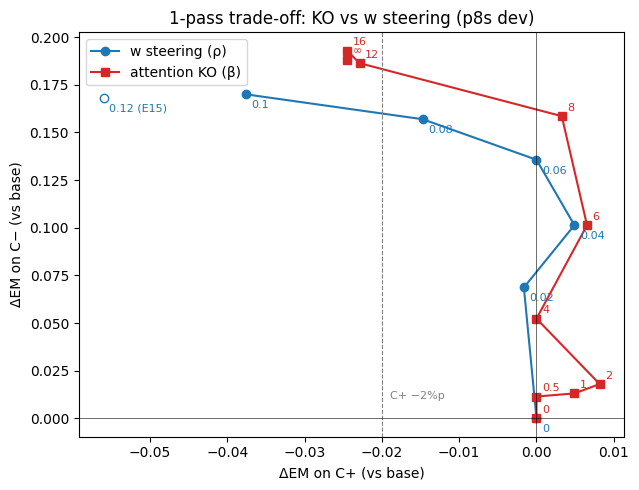

In [ ]:
## Cell 13 — nested β 선택 + A0 paired 비교 + w 대비 트레이드오프 곡선 (CPU, 30초)
import matplotlib.pyplot as plt

# ── ① fold (행 단위, 같은 질문의 C+/C−는 같은 fold)
FO2 = FO.rename(columns={'row': 'rid'}).sort_values('rid').reset_index(drop=True)
assert (FO2.question.values == m.question.values).all()
FOLD = FO2.fold.values

EMb = {b: score(d.raw.tolist(), d.rid.tolist()).em.values.astype(float) for b, d in GB.items()}
EMb[np.inf] = EMK['ko_pre_L14-18']               # β=∞ (bool 완전 차단, β1e4와 logit 동일 확인됨)
GRID = sorted(EMb)
e_base = EMb[0.0]

def lower_cplus(d, mask, B=2000, seed=0):
    x = d[mask]
    idx = np.random.RandomState(seed).randint(0, len(x), (B, len(x)))
    return np.percentile(x[idx].mean(1), 2.5)

# ── ② nested 안전 선택 (사전등록 규칙)
pol, sel = np.zeros(len(m)), {}
for k in range(5):
    tr, te = FOLD != k, FOLD == k
    ok = [b for b in GRID if lower_cplus(EMb[b] - e_base, tr & ~isCm) >= -0.02]
    best = max(ok, key=lambda b: EMb[b][tr].mean()) if ok else 0.0
    sel[k] = best
    pol[te] = EMb[best][te]
print('fold별 선택 β:', {k: (float(v) if np.isfinite(v) else 'inf') for k, v in sel.items()})

# ── ③ 주 판정
print(f'\nEM | base {e_base.mean():.4f} | A0 {emA.mean():.4f} | nested-KO {pol.mean():.4f} '
      f'(C− {pol[isCm].mean():.4f}, C+ {pol[~isCm].mean():.4f})')
print('[주1] nested-KO − A0   전체:', ciq(pol - emA), '| C−:', ciq(pol - emA, isCm), '| C+:', ciq(pol - emA, ~isCm))
print('[주2] nested-KO − base C+:', ciq(pol - e_base, ~isCm), '(비열등: 하한 ≥ −0.02)')
print('      nested-KO − base 전체:', ciq(pol - e_base), '| C−:', ciq(pol - e_base, isCm))
e8 = EMb[8.0]
print('[참고, 사후 선택] β8 − A0 전체:', ciq(e8 - emA), '| C−:', ciq(e8 - emA, isCm),
      '| C+ vs base:', ciq(e8 - e_base, ~isCm))

# ── ④ 셀 분해 (nested, A0)
rows = []
for c in ['K+C+', 'K−C+', 'K+C−', 'K−C−']:
    mk = CELL == c
    rows.append(dict(cell=c, n=int(mk.sum()), base=round(e_base[mk].mean(), 3),
                     dA0=round((emA - e_base)[mk].mean(), 3), d_nestedKO=round((pol - e_base)[mk].mean(), 3)))
print('\n', pd.DataFrame(rows).to_string(index=False))

# ── ⑤ 트레이드오프 곡선: KO β (E15 tierand 배치) vs w ρ (E15 원 배치)
ko_pts = [(float((EMb[b] - e_base)[~isCm].mean()), float((EMb[b] - e_base)[isCm].mean()), b) for b in GRID]
WF = {0.02: 'gen_w_r0.02_xfit_da36736f.parquet', 0.04: 'gen_w_r0.04_xfit_da36736f.parquet',
      0.06: 'gen_A0_r0.06_xfit_da36736f.parquet', 0.08: 'gen_w_r0.08_xfit_da36736f.parquet',
      0.10: 'gen_w_r0.1_xfit_da36736f.parquet'}
B_orig = pd.read_parquet(E15 / 'gen_base.parquet').rename(columns={'row': 'rid'}).sort_values('rid')
e_bo = score(B_orig.raw.tolist(), B_orig.rid.tolist()).em.values.astype(float)
w_pts = [(0.0, 0.0, 0.0)]
for rho, f in WF.items():
    try:
        d = pd.read_parquet(E15 / f).rename(columns={'row': 'rid'}).sort_values('rid')
        e = score(d.raw.tolist(), d.rid.tolist()).em.values.astype(float)
        w_pts.append((float((e - e_bo)[~isCm].mean()), float((e - e_bo)[isCm].mean()), rho))
    except Exception as ex:
        print('w 파일 누락:', f, ex)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([p[0] for p in w_pts], [p[1] for p in w_pts], 'o-', c='C0', label='w steering (ρ)')
for x, y, r in w_pts: ax.annotate(f'{r:g}', (x, y), textcoords='offset points', xytext=(4, -10), fontsize=8, color='C0')
ax.plot(-0.056, 0.168, 'o', c='C0', mfc='none'); ax.annotate('0.12 (E15)', (-0.056, 0.168), xytext=(4, -10), textcoords='offset points', fontsize=8, color='C0')
ax.plot([p[0] for p in ko_pts], [p[1] for p in ko_pts], 's-', c='C3', label='attention KO (β)')
for x, y, b in ko_pts: ax.annotate('∞' if not np.isfinite(b) else f'{b:g}', (x, y), textcoords='offset points', xytext=(4, 4), fontsize=8, color='C3')
ax.axvline(-0.02, c='gray', ls='--', lw=.8); ax.text(-0.019, 0.01, 'C+ −2%p', fontsize=8, color='gray')
ax.axhline(0, c='k', lw=.4); ax.axvline(0, c='k', lw=.4)
ax.set(xlabel='ΔEM on C+ (vs base)', ylabel='ΔEM on C− (vs base)', title='1-pass trade-off: KO vs w steering (p8s dev)')
ax.legend(); plt.tight_layout()
(OUT / 'figs').mkdir(exist_ok=True); plt.savefig(OUT / 'figs' / 'e17_2_frontier.png', dpi=150); plt.show()

json.dump(dict(sel={k: (float(v) if np.isfinite(v) else 'inf') for k, v in sel.items()},
               nested_EM=float(pol.mean()), A0_EM=float(emA.mean()), base_EM=float(e_base.mean())),
          open(OUT / 'e17_2_nested.json', 'w'), indent=1)

In [ ]:
## Cell 14 — [사후] 같은 nested 안전 규칙으로 w vs KO 맞대결 (CPU, 20초)
# w 격자: E15 원 배치 저장본(ρ 0~0.10), base = 원 배치 gen_base
EMw = {0.0: e_bo}
for rho, f in WF.items():
    d = pd.read_parquet(E15 / f).rename(columns={'row': 'rid'}).sort_values('rid')
    EMw[rho] = score(d.raw.tolist(), d.rid.tolist()).em.values.astype(float)

def nested(EMd, e0):
    pol, sel = np.zeros(len(m)), {}
    for k in range(5):
        tr, te = FOLD != k, FOLD == k
        ok = [g for g in sorted(EMd) if lower_cplus(EMd[g] - e0, tr & ~isCm) >= -0.02]
        best = max(ok, key=lambda g: EMd[g][tr].mean()) if ok else 0.0
        sel[k] = best; pol[te] = EMd[best][te]
    return pol, sel

pol_w, sel_w = nested(EMw, e_bo)
print('w  fold별 선택 ρ:', sel_w)
print('KO fold별 선택 β:', {k: (float(v) if np.isfinite(v) else 'inf') for k, v in sel.items()})
print(f'\nEM | nested-w {pol_w.mean():.4f} (C− {pol_w[isCm].mean():.4f}, C+ {pol_w[~isCm].mean():.4f})'
      f' | nested-KO {pol.mean():.4f} (C− {pol[isCm].mean():.4f}, C+ {pol[~isCm].mean():.4f})')
print('nested-KO − nested-w 전체:', ciq(pol - pol_w), '| C−:', ciq(pol - pol_w, isCm), '| C+:', ciq(pol - pol_w, ~isCm))
print('nested-w − base C+:', ciq(pol_w - e_bo, ~isCm), '| nested-KO − base C+:', ciq(pol - e_base, ~isCm))
print('base 배치 차이(원 vs tierand) 문자열 불일치 행:', int((B_orig.raw.values != B0.raw.values).sum()))

w  fold별 선택 ρ: {0: 0.06, 1: 0.04, 2: 0.06, 3: 0.04, 4: 0.04}
KO fold별 선택 β: {0: 8.0, 1: 6.0, 2: 6.0, 3: 2.0, 4: 6.0}

EM | nested-w 0.5858 (C− 0.3725, C+ 0.7990) | nested-KO 0.5768 (C− 0.3529, C+ 0.8007)
nested-KO − nested-w 전체: -0.0090 [-0.0253, +0.0074] | C−: -0.0196 [-0.0441, +0.0049] | C+: +0.0016 [-0.0180, +0.0229]
nested-w − base C+: -0.0033 [-0.0180, +0.0131] | nested-KO − base C+: +0.0000 [-0.0196, +0.0196]
base 배치 차이(원 vs tierand) 문자열 불일치 행: 3


## 음?

In [ ]:
## Cell 15 — packed 시퀀스 동치성 검증: A끝 = 문맥 런, B끝 = CB 런 (A100 20초 / L4 40초)
CUSTOM = {'mask': None}
def custom_prehook(mod, args, kwargs):
    if CUSTOM['mask'] is None or kwargs['hidden_states'].shape[1] == 1:
        return None
    kwargs['attention_mask'] = CUSTOM['mask']
    return args, kwargs
CUSTOM_HOOKS = [LAYERS[l].self_attn.register_forward_pre_hook(custom_prehook, with_kwargs=True)
                for l in range(len(LAYERS))]

def pack_batch(b):
    A = [IDS[r] for r in b]
    Q = [IDS_CB[r][1:] for r in b]                        # CB 프롬프트에서 BOS 제외
    assert all(IDS_CB[r][0] == TOK.bos_token_id for r in b)
    T = max(len(a) + len(q) for a, q in zip(A, Q))
    n = len(b)
    ids  = torch.full((n, T), TOK.pad_token_id, dtype=torch.long)
    pos  = torch.zeros((n, T), dtype=torch.long)
    mask = torch.zeros((n, 1, T, T), dtype=torch.bool)
    endA, endB = [], []
    for i, (a, q) in enumerate(zip(A, Q)):
        nA, nB = len(a), len(q); pad = T - nA - nB
        ids[i, pad:pad + nA] = torch.tensor(a); ids[i, pad + nA:] = torch.tensor(q)
        pos[i, pad:pad + nA] = torch.arange(nA)
        pos[i, pad + nA:] = torch.arange(1, nB + 1)        # CB 프롬프트와 같은 위치 번호
        sa, sb = slice(pad, pad + nA), slice(pad + nA, T)
        mask[i, 0, sa, sa] = torch.ones(nA, nA, dtype=torch.bool).tril()
        mask[i, 0, sb, sb] = torch.ones(nB, nB, dtype=torch.bool).tril()
        mask[i, 0, sb, pad] = True                           # B는 BOS만 공유
        for p in range(pad):
            mask[i, 0, p, p] = True                          # 패딩 행 NaN 방지
        endA.append(pad + nA - 1); endB.append(T - 1)
    return ids, pos, mask, endA, endB

@torch.inference_mode()
def packed_logits(b):
    ids, pos, mask, endA, endB = pack_batch(b)
    CUSTOM['mask'] = mask.cuda()
    try:
        lg = MODEL(input_ids=ids.cuda(), position_ids=pos.cuda()).logits.float()
    finally:
        CUSTOM['mask'] = None
    r = torch.arange(len(b))
    return lg[r, endA], lg[r, endB]

@torch.inference_mode()
def plain_logits(id_lists):
    bt = TOK.pad({'input_ids': id_lists}, padding=True, return_tensors='pt')
    return MODEL(input_ids=bt['input_ids'].cuda(),
                 attention_mask=bt['attention_mask'].cuda()).logits[:, -1].float()

for name, b in [('첫 배치', BATCH_E15[0]), ('중간 배치', BATCH_E15[38]), ('패딩없는 배치', flat[0])]:
    la, lb = packed_logits(b)
    ra = plain_logits([IDS[r] for r in b])
    rb = plain_logits([IDS_CB[r] for r in b])
    print(f'{name:8s} | A끝 vs 문맥런: max|Δ| {(la - ra).abs().max().item():.3f}, '
          f'top1 일치 {(la.argmax(-1) == ra.argmax(-1)).float().mean().item():.3f} '
          f'| B끝 vs CB런: max|Δ| {(lb - rb).abs().max().item():.3f}, '
          f'top1 일치 {(lb.argmax(-1) == rb.argmax(-1)).float().mean().item():.3f}')

extra = np.mean([len(IDS_CB[r]) - 1 for r in range(len(m))]) / np.mean([len(i) for i in IDS])
print(f'추가 prefill 토큰 비율: +{extra:.1%}')

첫 배치     | A끝 vs 문맥런: max|Δ| 0.344, top1 일치 1.000 | B끝 vs CB런: max|Δ| 0.379, top1 일치 1.000
중간 배치    | A끝 vs 문맥런: max|Δ| 0.594, top1 일치 0.938 | B끝 vs CB런: max|Δ| 0.442, top1 일치 0.875
패딩없는 배치  | A끝 vs 문맥런: max|Δ| 0.438, top1 일치 1.000 | B끝 vs CB런: max|Δ| 0.438, top1 일치 1.000
추가 prefill 토큰 비율: +39.0%


In [ ]:
## Cell 16 — packed prefill 특징으로 C 판별 (A100 1분 / L4 2.5분)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

@torch.inference_mode()
def packed_ends(b):
    ids, pos, mask, endA, endB = pack_batch(b)
    CUSTOM['mask'] = mask.cuda()
    try:
        h = MODEL.model(input_ids=ids.cuda(), position_ids=pos.cuda()).last_hidden_state
    finally:
        CUSTOM['mask'] = None
    r = torch.arange(len(b))
    return (MODEL.lm_head(h[r, endA]).float().log_softmax(-1),
            MODEL.lm_head(h[r, endB]).float().log_softmax(-1))

p_feat = OUT / 'packed_feats.parquet'
if p_feat.exists():
    PF = pd.read_parquet(p_feat)
else:
    rows, t0 = [], time.time()
    for b in BATCH_E15:
        la, lb = packed_ends(b)
        ta, tb = la.argmax(-1), lb.argmax(-1)
        r = torch.arange(len(b))
        f = dict(maxA=la.max(-1).values, maxB=lb.max(-1).values, agree=(ta == tb).float(),
                 A_of_B=la[r, tb], B_of_A=lb[r, ta],
                 entA=-(la.exp() * la).sum(-1), entB=-(lb.exp() * lb).sum(-1),
                 topA=ta.float(), topB=tb.float())
        f = {k: v.cpu().numpy() for k, v in f.items()}
        rows += [dict(rid=rid, **{k: f[k][i] for k in f}) for i, rid in enumerate(b)]
    PF = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    PF.to_parquet(p_feat)
    print(f'prefill {time.time() - t0:.0f}s')

# ── 동치성 전수 확인: A끝 top1 = base 첫 토큰, B끝 top1 = CB 첫 토큰
first_tok = lambda s: TOK(s, add_special_tokens=False)['input_ids'][:1] or [-1]
ftA = np.array([first_tok(x)[0] for x in GK['base_mask'].raw])
ftB = {r: first_tok(x)[0] for r, x in zip(CB.rid, CB.cb_raw)}
print(f'A끝 top1 = base 첫 토큰: {np.mean(PF.topA.values == ftA):.3f} (1224행) | '
      f'B끝 top1 = CB 첫 토큰: {np.mean([PF.topB[r] == ftB[r] for r in RID_CM]):.3f} (C− 612행)')

# ── 판별: y = C−
FEAT = ['maxA', 'maxB', 'agree', 'A_of_B', 'B_of_A', 'entA', 'entB']
X, y = PF[FEAT].values, isCm.astype(int)
oof = np.zeros(len(y))
for k in range(5):
    tr, te = FOLD != k, FOLD == k
    sc = StandardScaler().fit(X[tr])
    clf = LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(X[tr]), y[tr])
    oof[te] = clf.predict_proba(sc.transform(X[te]))[:, 1]

def auc_ci(s, B=1000, seed=0):
    rs = np.random.RandomState(seed); qs = np.unique(QI)
    rowsQ = {q: np.where(QI == q)[0] for q in qs}
    bs = []
    for _ in range(B):
        idx = np.concatenate([rowsQ[q] for q in rs.choice(qs, len(qs))])
        bs.append(roc_auc_score(y[idx], s[idx]))
    return roc_auc_score(y, s), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

print('\n[판별기 AUROC, y=C−]  (비교: E15 L13 hidden 판독기 0.904)')
print('  7특징 로지스틱 OOF   : %.3f [%.3f, %.3f]' % auc_ci(oof))
for f, sgn in [('agree', -1), ('B_of_A', -1), ('A_of_B', +1), ('maxB', +1), ('maxA', -1)]:
    print(f'  단일 {f:7s} (부호 {sgn:+d}): %.3f' % roc_auc_score(y, sgn * PF[f].values))

# ── 셀별 판별 점수 분포 (어디서 헷갈리는가)
print('\n셀별 OOF P(C−) 평균:', {c: round(oof[CELL == c].mean(), 3) for c in ['K+C+', 'K−C+', 'K+C−', 'K−C−']})

prefill 32s
A끝 top1 = base 첫 토큰: 0.995 (1224행) | B끝 top1 = CB 첫 토큰: 0.971 (C− 612행)

[판별기 AUROC, y=C−]  (비교: E15 L13 hidden 판독기 0.904)
  7특징 로지스틱 OOF   : 0.781 [0.759, 0.806]
  단일 agree   (부호 -1): 0.607
  단일 B_of_A  (부호 -1): 0.690
  단일 A_of_B  (부호 +1): 0.392
  단일 maxB    (부호 +1): 0.500
  단일 maxA    (부호 -1): 0.682

셀별 OOF P(C−) 평균: {'K+C+': np.float64(0.358), 'K−C+': np.float64(0.443), 'K+C−': np.float64(0.618), 'K−C−': np.float64(0.582)}


In [ ]:
## Cell 17 — 판별 목표 재정의 + packed 선택 정책 오프라인 평가 (CPU, 10초)
cb_row = Krow.astype(float)                       # 행별 CB 답 EM (K_strict와 동일 정의)
ctx_row = emB                                     # 문맥 답(base_mask) EM
dec = cb_row != ctx_row                           # 결정적 행
dis = PF.agree.values == 0                        # 첫 토큰이 갈린 행
print(f'결정적 행 {dec.sum()} (C− {(dec & isCm).sum()}, C+ {(dec & ~isCm).sum()}) '
      f'| 그중 첫 토큰 갈림 {np.mean(dis[dec]):.3f}')

# ── ① 올바른 목표: 결정적 행에서 "CB가 맞는 쪽인가"
yD = cb_row
oofD = np.full(len(y), np.nan)
for k in range(5):
    tr, te = (FOLD != k) & dec, FOLD == k
    sc = StandardScaler().fit(X[tr])
    clf = LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(X[tr]), yD[tr])
    oofD[te] = clf.predict_proba(sc.transform(X[te]))[:, 1]
aucD = lambda s: roc_auc_score(yD[dec], s[dec])
print('\n[선택 AUROC, 결정적 행, y=CB가 정답]')
print(f'  7특징 로지스틱 OOF : {aucD(oofD):.3f}')
print(f'  maxB − maxA (튜닝 0): {aucD(PF.maxB.values - PF.maxA.values):.3f}')
print(f'  B_of_A (부호 −)    : {aucD(-PF.B_of_A.values):.3f}')

# ── ② 선택 정책
POL = {
    'base(문맥 답)': ctx_row,
    'R2-첫토큰': np.where(dis & (PF.maxB.values > PF.maxA.values), cb_row, ctx_row),
    '학습 선택기': np.where(dis & (oofD > 0.5), cb_row, ctx_row),
    '후보 oracle': np.maximum(cb_row, ctx_row),
}
rows = []
for name, e in POL.items():
    acc = np.mean((e == 1)[dec]) if dec.any() else np.nan
    rows.append(dict(policy=name, EM=round(e.mean(), 4), C_minus=round(e[isCm].mean(), 4),
                     C_plus=round(e[~isCm].mean(), 4), sel_acc_Cm=round(np.mean((e == 1)[dec & isCm]), 3),
                     sel_acc_Cp=round(np.mean((e == 1)[dec & ~isCm]), 3),
                     vs_A0=ciq(e - emA), Cplus_vs_base=ciq(e - ctx_row, ~isCm)))
print('\n', pd.DataFrame(rows).to_string(index=False))
print('참고: A0 0.598 | nested-w 0.586 | N R2(전체 답 확신도) 0.608 | E2 0.645')

결정적 행 417 (C− 193, C+ 224) | 그중 첫 토큰 갈림 0.942

[선택 AUROC, 결정적 행, y=CB가 정답]
  7특징 로지스틱 OOF : 0.947
  maxB − maxA (튜닝 0): 0.889
  B_of_A (부호 −)    : 0.822

     policy     EM  C_minus  C_plus  sel_acc_Cm  sel_acc_Cp                      vs_A0              Cplus_vs_base
base(문맥 답) 0.5302   0.2598  0.8007       0.093       0.888 -0.0678 [-0.0842, -0.0507] +0.0000 [+0.0000, +0.0000]
    R2-첫토큰 0.6078   0.4036  0.8121       0.549       0.920 +0.0098 [-0.0090, +0.0294] +0.0114 [-0.0049, +0.0278]
    학습 선택기 0.6495   0.4886  0.8105       0.819       0.915 +0.0515 [+0.0310, +0.0735] +0.0098 [-0.0082, +0.0278]
 후보 oracle 0.6936   0.5458  0.8415       1.000       1.000 +0.0956 [+0.0735, +0.1176] +0.0408 [+0.0261, +0.0572]
참고: A0 0.598 | nested-w 0.586 | N R2(전체 답 확신도) 0.608 | E2 0.645


In [ ]:
## Cell 18 — 사전등록 + packed 선택 생성(실제 실행) + 오프라인 대조 (A100 2분 / L4 5분)
# ── ① 사전등록
PRE3 = dict(
    exp='E17-3 packed 1-forward 선택 생성: [문맥 프롬프트]+[CB 프롬프트(BOS 공유, 마스크 분리)] prefill 1회 → '
        '학습 선택기로 분기 선택 → 선택 분기만 decode',
    date='2026-10-05', status='탐색적 설계(Cell 16·17 결과 후), 실행 사양은 아래로 고정',
    selector='특징 7개(maxA,maxB,agree,A_of_B,B_of_A,entA,entB) StandardScaler+LogisticRegression(C=1), '
             'fold k 밖의 결정적 행(CB EM≠문맥 EM)으로 학습, 첫 토큰 갈림 & p>0.5면 B 분기',
    primary=['실행 EM − A0 (전체, 질문 단위 paired)', '실행 C+ 비열등 (vs base, 하한 ≥ −0.02)'],
    secondary=['실행 vs 오프라인 정책 일치율·EM 차', '지연시간: packed 실행 vs base 생성'],
    labels='선택기 학습에 dev gold 사용(사전 단계), 추론 시 라벨 불필요',
    env=ENV, model_rev=REV)
p_pre3 = OUT / 'prereg_e17_3.json'
if not p_pre3.exists():
    p_pre3.write_text(json.dumps(PRE3, ensure_ascii=False, indent=1))
print('prereg sha', sha(p_pre3)[:12])

# ── ② fold별 선택기 (Cell 17과 동일 사양)
SEL = {}
for k in range(5):
    tr = (FOLD != k) & dec
    sc = StandardScaler().fit(X[tr])
    SEL[k] = (sc, LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(X[tr]), yD[tr]))

# ── ③ 훅 교체: prefill/decode 모두 CUSTOM 마스크 사용
for h in CUSTOM_HOOKS:
    h.remove()
CUSTOM = {'mask': None}
def custom_prehook2(mod, args, kwargs):
    if CUSTOM['mask'] is None:
        return None
    kwargs['attention_mask'] = CUSTOM['mask']
    return args, kwargs
CUSTOM_HOOKS = [LAYERS[l].self_attn.register_forward_pre_hook(custom_prehook2, with_kwargs=True)
                for l in range(len(LAYERS))]

@torch.inference_mode()
def packed_generate(b, max_new=MAX_NEW_TOKENS):
    ids, pos, mask, endA, endB = pack_batch(b)
    n, T = ids.shape
    nA = [len(IDS[r]) for r in b]; nB = [len(IDS_CB[r]) - 1 for r in b]
    pads = [T - a - q for a, q in zip(nA, nB)]
    CUSTOM['mask'] = mask.cuda()
    try:
        out = MODEL.model(input_ids=ids.cuda(), position_ids=pos.cuda(), use_cache=True)
        h, pkv = out.last_hidden_state, out.past_key_values
        r = torch.arange(n)
        la = MODEL.lm_head(h[r, endA]).float().log_softmax(-1)
        lb = MODEL.lm_head(h[r, endB]).float().log_softmax(-1)
        ta, tb = la.argmax(-1), lb.argmax(-1)
        f = torch.stack([la.max(-1).values, lb.max(-1).values, (ta == tb).float(), la[r, tb], lb[r, ta],
                         -(la.exp() * la).sum(-1), -(lb.exp() * lb).sum(-1)], 1).cpu().numpy()
        useB = np.zeros(n, bool)
        for i, rid in enumerate(b):
            sc, clf = SEL[FOLD[rid]]
            p = clf.predict_proba(sc.transform(f[i:i + 1]))[0, 1]
            useB[i] = (f[i, 2] == 0) and (p > 0.5)
        # 분기별 허용 key (prefill 구간)
        allow = torch.zeros((n, T), dtype=torch.bool)
        nxt_pos = torch.zeros(n, dtype=torch.long)
        for i in range(n):
            if useB[i]:
                allow[i, pads[i]] = True; allow[i, pads[i] + nA[i]:] = True; nxt_pos[i] = nB[i] + 1
            else:
                allow[i, pads[i]:pads[i] + nA[i]] = True; nxt_pos[i] = nA[i]
        allow = allow.cuda(); nxt_pos = nxt_pos.cuda()
        tok = torch.where(torch.tensor(useB, device=tb.device), tb, ta)
        gen = [tok]
        done = torch.tensor([t.item() in EOS for t in tok], device=tok.device)
        for t in range(1, max_new):
            if done.all():
                break
            allow = torch.cat([allow, torch.ones((n, 1), dtype=torch.bool, device=allow.device)], 1)
            CUSTOM['mask'] = allow[:, None, None, :]
            o = MODEL.model(input_ids=tok[:, None], position_ids=(nxt_pos + t - 1)[:, None],
                            past_key_values=pkv, use_cache=True)
            pkv = o.past_key_values
            tok = MODEL.lm_head(o.last_hidden_state[:, -1]).argmax(-1)
            tok = torch.where(done, torch.full_like(tok, TOK.pad_token_id), tok)
            gen.append(tok)
            done = done | torch.tensor([x.item() in EOS for x in tok], device=tok.device)
    finally:
        CUSTOM['mask'] = None
    g = torch.stack(gen, 1).cpu().numpy()
    k = [next((j for j, x in enumerate(row) if x in EOS), len(row)) for row in g]
    return [TOK.decode(row[:kk].tolist(), **DECODE_KW) for row, kk in zip(g, k)], useB, k

# ── ④ 실행 (체크포인트)
p_ex = OUT / 'gen' / 'packed_select.parquet'
if p_ex.exists():
    PX = pd.read_parquet(p_ex)
else:
    rows, t0 = [], time.time()
    for b in BATCH_E15:
        raws, useB, k = packed_generate(b)
        rows += [dict(rid=r, raw=x, useB=bool(u), n_gen=kk) for r, x, u, kk in zip(b, raws, useB, k)]
    PX = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    PX.to_parquet(p_ex)
    print(f'packed 실행 {time.time() - t0:.0f}s (참고: base 생성 51s)')

# ── ⑤ 평가
emX = score(PX.raw.tolist(), PX.rid.tolist()).em.values.astype(float)
pol_off = POL['학습 선택기']
selB_off = dis & (oofD > 0.5)
print(f'\n선택 일치(실행 vs 오프라인): {np.mean(PX.useB.values == selB_off):.3f} | B 선택 비율 {PX.useB.mean():.3f}')
print(f'EM 일치 행: {np.mean(emX == pol_off):.3f} | 실행 − 오프라인: {ciq(emX - pol_off)}')
print(f'\n실행 EM {emX.mean():.4f} (C− {emX[isCm].mean():.4f}, C+ {emX[~isCm].mean():.4f}) | hit {np.mean(PX.n_gen >= MAX_NEW_TOKENS):.3f}')
print('[주1] 실행 − A0 전체:', ciq(emX - emA), '| C−:', ciq(emX - emA, isCm), '| C+:', ciq(emX - emA, ~isCm))
print('[주2] 실행 − base C+:', ciq(emX - emB, ~isCm), '(비열등: 하한 ≥ −0.02)')

prereg sha 0f4158f92ed8
packed 실행 61s (참고: base 생성 51s)

선택 일치(실행 vs 오프라인): 1.000 | B 선택 비율 0.255
EM 일치 행: 0.997 | 실행 − 오프라인: -0.0016 [-0.0049, +0.0016]

실행 EM 0.6479 (C− 0.4837, C+ 0.8121) | hit 0.000
[주1] 실행 − A0 전체: +0.0498 [+0.0294, +0.0711] | C−: +0.0899 [+0.0588, +0.1225] | C+: +0.0098 [-0.0114, +0.0310]
[주2] 실행 − base C+: +0.0114 [-0.0065, +0.0310] (비열등: 하한 ≥ −0.02)


In [ ]:
## Cell 19 — 라벨 효율 곡선 + 특징 ablation (CPU, 1분)
def policy_from(cols, n_sub=None, seed=0):
    Xi, p = PF[cols].values, np.zeros(len(m))
    rs = np.random.RandomState(seed)
    for k in range(5):
        tr = np.where((FOLD != k) & dec)[0]
        if n_sub is not None and n_sub < len(tr):
            for _ in range(100):                                   # 한 클래스만 뽑히면 재추첨
                s = rs.choice(tr, n_sub, replace=False)
                if 0 < yD[s].mean() < 1: break
            tr = s
        sc = StandardScaler().fit(Xi[tr])
        clf = LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(Xi[tr]), yD[tr])
        te = np.where(FOLD == k)[0]
        p[te] = clf.predict_proba(sc.transform(Xi[te]))[:, 1]
    return p, np.where(dis & (p > 0.5), cb_row, ctx_row)

# ── ① 라벨 효율 곡선
print('[라벨 효율] n = fold당 학습에 쓴 결정적 행 수 (seed 20, 평균 [5%, 95%])')
print(f'  n=0 (R2-첫토큰, 튜닝 없음): EM {POL["R2-첫토큰"].mean():.4f}')
curve = []
for n in [8, 16, 32, 64, 128, None]:
    res = [policy_from(FEAT, n, s) for s in (range(20) if n else [0])]
    aucs = np.array([aucD(p) for p, _ in res]); ems = np.array([e.mean() for _, e in res])
    cps = np.array([(e - ctx_row)[~isCm].mean() for _, e in res])
    lab = f'{n:>4d} (질문≈{n / 0.68:.0f})' if n else ' 전체 (≈333)'
    print(f'  n={lab} | AUROC {aucs.mean():.3f} [{np.percentile(aucs, 5):.3f}, {np.percentile(aucs, 95):.3f}] '
          f'| EM {ems.mean():.4f} [{np.percentile(ems, 5):.4f}, {np.percentile(ems, 95):.4f}] '
          f'| C+ Δ {cps.mean():+.4f} | A0 초과 seed 비율 {np.mean(ems > emA.mean()):.2f}')
    curve.append(dict(n=n or 'all', auc=aucs.mean(), em=ems.mean(), em_lo=np.percentile(ems, 5),
                      em_hi=np.percentile(ems, 95), cplus=cps.mean()))
pd.DataFrame(curve).to_csv(OUT / 'e17_3_label_curve.csv', index=False)

# ── ② 특징 ablation (전체 학습 행)
SETS = {'전체 7개': FEAT,
        '확신도만 (maxA,maxB)': ['maxA', 'maxB'],
        '확신도+agree': ['maxA', 'maxB', 'agree'],
        '교차확률만 (A_of_B,B_of_A)': ['A_of_B', 'B_of_A'],
        '교차확률 제외': ['maxA', 'maxB', 'agree', 'entA', 'entB'],
        '엔트로피 제외': ['maxA', 'maxB', 'agree', 'A_of_B', 'B_of_A']}
p_full, e_full = policy_from(FEAT)
print('\n[특징 ablation]')
rows = []
for name, cols in SETS.items():
    p, e = policy_from(cols)
    rows.append(dict(set=name, AUROC=round(aucD(p), 3), EM=round(e.mean(), 4),
                     sel_acc_Cm=round(np.mean((e == 1)[dec & isCm]), 3),
                     vs_full=ciq(e - e_full), vs_A0=ciq(e - emA)))
print(pd.DataFrame(rows).to_string(index=False))

# ── ③ 전체 모델 표준화 계수 (fold 평균) — 어떤 방향으로 CB를 고르는가
coef = []
for k in range(5):
    tr = (FOLD != k) & dec
    sc = StandardScaler().fit(X[tr])
    coef.append(LogisticRegression(C=1.0, max_iter=2000).fit(sc.transform(X[tr]), yD[tr]).coef_[0])
coef = np.array(coef)
print('\n[표준화 계수, + = CB 선택 쪽]')
for f, mu, sd in zip(FEAT, coef.mean(0), coef.std(0)):
    print(f'  {f:7s} {mu:+.2f} (fold sd {sd:.2f})')

[라벨 효율] n = fold당 학습에 쓴 결정적 행 수 (seed 20, 평균 [5%, 95%])
  n=0 (R2-첫토큰, 튜닝 없음): EM 0.6078
  n=   8 (질문≈12) | AUROC 0.868 [0.831, 0.911] | EM 0.6164 [0.6061, 0.6283] | C+ Δ -0.0216 | A0 초과 seed 비율 1.00
  n=  16 (질문≈24) | AUROC 0.912 [0.897, 0.930] | EM 0.6329 [0.6241, 0.6415] | C+ Δ -0.0069 | A0 초과 seed 비율 1.00
  n=  32 (질문≈47) | AUROC 0.922 [0.910, 0.936] | EM 0.6381 [0.6324, 0.6455] | C+ Δ -0.0020 | A0 초과 seed 비율 1.00
  n=  64 (질문≈94) | AUROC 0.932 [0.921, 0.939] | EM 0.6414 [0.6370, 0.6463] | C+ Δ +0.0023 | A0 초과 seed 비율 1.00
  n= 128 (질문≈188) | AUROC 0.942 [0.931, 0.948] | EM 0.6455 [0.6429, 0.6487] | C+ Δ +0.0057 | A0 초과 seed 비율 1.00
  n= 전체 (≈333) | AUROC 0.947 [0.947, 0.947] | EM 0.6495 [0.6495, 0.6495] | C+ Δ +0.0098 | A0 초과 seed 비율 1.00

[특징 ablation]
                  set  AUROC     EM  sel_acc_Cm                    vs_full                      vs_A0
                전체 7개  0.947 0.6495       0.819 +0.0000 [+0.0000, +0.0000] +0.0515 [+0.0310, +0.0735]
     확신도만 (maxA,maxB)  0.88

In [ ]:
## Cell 20 — 라벨 0개 고정 규칙 (파라미터·임계값 없음) (CPU, 5초)
A_B, B_A, mA, mB = PF.A_of_B.values, PF.B_of_A.values, PF.maxA.values, PF.maxB.values
RULE = {'X1: A_of_B > B_of_A': A_B - B_A,
        'X2: 상대확률 비교': (A_B - mA) - (B_A - mB),
        'R2-첫토큰: maxB > maxA': mB - mA}
rows = []
for name, s in RULE.items():
    e = np.where(dis & (s > 0), cb_row, ctx_row)
    rows.append(dict(rule=name, AUROC=round(aucD(s), 3), EM=round(e.mean(), 4),
                     C_minus=round(e[isCm].mean(), 4), C_plus=round(e[~isCm].mean(), 4),
                     sel_acc_Cm=round(np.mean((e == 1)[dec & isCm]), 3),
                     sel_acc_Cp=round(np.mean((e == 1)[dec & ~isCm]), 3),
                     B_rate=round(np.mean(dis & (s > 0)), 3),
                     vs_A0=ciq(e - emA), vs_learned=ciq(e - emX), Cplus_vs_base=ciq(e - ctx_row, ~isCm)))
print(pd.DataFrame(rows).to_string(index=False))
print(f'\n참고: 학습 선택기 실행 {emX.mean():.4f} (B 선택 {PX.useB.mean():.3f}) | A0 {emA.mean():.4f} | E2 0.645')

# 학습 선택기 대비 어디서 갈리는가 (X1 기준)
e1 = np.where(dis & (RULE['X1: A_of_B > B_of_A'] > 0), cb_row, ctx_row)
diff = e1 != emX
print('X1 vs 학습 선택기 EM이 갈린 행:', int(diff.sum()), '| 셀별:', pd.Series(CELL[diff]).value_counts().to_dict(),
      '| X1이 맞은 쪽:', int(((e1 == 1) & diff).sum()))

               rule  AUROC     EM  C_minus  C_plus  sel_acc_Cm  sel_acc_Cp  B_rate                      vs_A0                 vs_learned              Cplus_vs_base
X1: A_of_B > B_of_A  0.929 0.6348   0.4542  0.8154       0.710       0.929   0.209 +0.0368 [+0.0180, +0.0564] -0.0131 [-0.0221, -0.0041] +0.0147 [-0.0033, +0.0327]
        X2: 상대확률 비교  0.936 0.6340   0.4510  0.8170       0.699       0.933   0.201 +0.0359 [+0.0172, +0.0556] -0.0139 [-0.0237, -0.0049] +0.0163 [+0.0000, +0.0327]
R2-첫토큰: maxB > maxA  0.889 0.6078   0.4036  0.8121       0.549       0.920   0.151 +0.0098 [-0.0090, +0.0294] -0.0400 [-0.0531, -0.0278] +0.0114 [-0.0049, +0.0278]

참고: 학습 선택기 실행 0.6479 (B 선택 0.255) | A0 0.5980 | E2 0.645
X1 vs 학습 선택기 EM이 갈린 행: 34 | 셀별: {'K+C−': 25, 'K−C+': 8, 'K−C−': 1} | X1이 맞은 쪽: 9


In [ ]:
## Cell 21 — 사전등록 → X1 packed 실제 실행 → 단일 질문 지연시간 (A100 3분 / L4 7분)
# ── ① 사전등록 (X1 사양 고정)
PRE4 = dict(exp='E17-4 packed 1-forward + 라벨 0개 규칙 X1 실행',
            date='2026-10-05', status='탐색적 규칙(Cell 19 계수 후 설계), 실행 사양 고정',
            rule='첫 토큰이 갈리고 log P_A(top1_B) > log P_B(top1_A)이면 B(closed-book) 분기, 아니면 A',
            primary=['실행 EM − A0', '실행 C+ 비열등(하한 ≥ −0.02)'],
            secondary=['실행 vs 오프라인 일치', '지연시간(bs1, 100질문): base vs packed'],
            labels='없음 (학습·튜닝 파라미터 0)', env=ENV, model_rev=REV)
p_pre4 = OUT / 'prereg_e17_4.json'
if not p_pre4.exists():
    p_pre4.write_text(json.dumps(PRE4, ensure_ascii=False, indent=1))
print('prereg sha', sha(p_pre4)[:12])

# ── ② packed 생성 일반화: 선택 함수만 바꿔 끼움
choose_X1 = lambda f, b: (f[:, 2] == 0) & (f[:, 3] > f[:, 4])          # agree==0 & A_of_B > B_of_A
def choose_learned(f, b):
    out = np.zeros(len(b), bool)
    for i, rid in enumerate(b):
        sc, clf = SEL[FOLD[rid]]
        out[i] = (f[i, 2] == 0) and clf.predict_proba(sc.transform(f[i:i + 1]))[0, 1] > 0.5
    return out

@torch.inference_mode()
def packed_gen(b, choose, max_new=MAX_NEW_TOKENS):
    ids, pos, mask, endA, endB = pack_batch(b)
    n, T = ids.shape
    nA = [len(IDS[r]) for r in b]; nB = [len(IDS_CB[r]) - 1 for r in b]
    pads = [T - a - q for a, q in zip(nA, nB)]
    CUSTOM['mask'] = mask.cuda()
    try:
        o = MODEL.model(input_ids=ids.cuda(), position_ids=pos.cuda(), use_cache=True)
        h, pkv = o.last_hidden_state, o.past_key_values
        r = torch.arange(n)
        la = MODEL.lm_head(h[r, endA]).float().log_softmax(-1)
        lb = MODEL.lm_head(h[r, endB]).float().log_softmax(-1)
        ta, tb = la.argmax(-1), lb.argmax(-1)
        f = torch.stack([la.max(-1).values, lb.max(-1).values, (ta == tb).float(), la[r, tb], lb[r, ta],
                         -(la.exp() * la).sum(-1), -(lb.exp() * lb).sum(-1)], 1).cpu().numpy()
        useB = choose(f, b)
        allow = torch.zeros((n, T), dtype=torch.bool); nxt = torch.zeros(n, dtype=torch.long)
        for i in range(n):
            if useB[i]:
                allow[i, pads[i]] = True; allow[i, pads[i] + nA[i]:] = True; nxt[i] = nB[i] + 1
            else:
                allow[i, pads[i]:pads[i] + nA[i]] = True; nxt[i] = nA[i]
        allow, nxt = allow.cuda(), nxt.cuda()
        tok = torch.where(torch.tensor(useB, device=tb.device), tb, ta)
        gen = [tok]
        eos_t = torch.tensor(sorted(EOS), device=tok.device)
        done = torch.isin(tok, eos_t)
        for t in range(1, max_new):
            if done.all():
                break
            allow = torch.cat([allow, torch.ones((n, 1), dtype=torch.bool, device=allow.device)], 1)
            CUSTOM['mask'] = allow[:, None, None, :]
            o = MODEL.model(input_ids=tok[:, None], position_ids=(nxt + t - 1)[:, None],
                            past_key_values=pkv, use_cache=True)
            pkv = o.past_key_values
            tok = MODEL.lm_head(o.last_hidden_state[:, -1]).argmax(-1)
            tok = torch.where(done, torch.full_like(tok, TOK.pad_token_id), tok)
            gen.append(tok)
            done = done | torch.isin(tok, eos_t)
    finally:
        CUSTOM['mask'] = None
    g = torch.stack(gen, 1).cpu().numpy()
    k = [next((j for j, x in enumerate(row) if x in EOS), len(row)) for row in g]
    return [TOK.decode(row[:kk].tolist(), **DECODE_KW) for row, kk in zip(g, k)], useB, k

# ── ③ X1 실행 (E15 배치, 체크포인트)
p_x1 = OUT / 'gen' / 'packed_X1.parquet'
if p_x1.exists():
    PX1 = pd.read_parquet(p_x1)
else:
    rows, t0 = [], time.time()
    for b in BATCH_E15:
        raws, useB, k = packed_gen(b, choose_X1)
        rows += [dict(rid=r, raw=x, useB=bool(u), n_gen=kk) for r, x, u, kk in zip(b, raws, useB, k)]
    PX1 = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    PX1.to_parquet(p_x1)
    print(f'X1 packed 실행 {time.time() - t0:.0f}s (base 51s, 학습 선택기 61s)')

emX1 = score(PX1.raw.tolist(), PX1.rid.tolist()).em.values.astype(float)
off_X1 = np.where(dis & (RULE['X1: A_of_B > B_of_A'] > 0), cb_row, ctx_row)
print(f'\n선택 일치(실행 vs 오프라인) {np.mean(PX1.useB.values == (dis & (RULE["X1: A_of_B > B_of_A"] > 0))):.3f} '
      f'| EM 일치 {np.mean(emX1 == off_X1):.3f}')
print(f'X1 실행 EM {emX1.mean():.4f} (C− {emX1[isCm].mean():.4f}, C+ {emX1[~isCm].mean():.4f}) '
      f'| hit {np.mean(PX1.n_gen >= MAX_NEW_TOKENS):.3f}')
print('[주1] X1 실행 − A0:', ciq(emX1 - emA), '| C−:', ciq(emX1 - emA, isCm), '| C+:', ciq(emX1 - emA, ~isCm))
print('[주2] X1 실행 − base C+:', ciq(emX1 - emB, ~isCm), '(하한 ≥ −0.02)')
print('     학습 선택기 실행 − X1 실행:', ciq(emX - emX1))

# ── ④ 단일 질문 지연시간 (bs1, 무작위 100질문의 C− 행, 워밍업 5회)
rs = np.random.RandomState(1); lat_rows = rs.choice(RID_CM, 100, replace=False)
for r in lat_rows[:5]:
    generate([IDS[r]]); packed_gen([r], choose_X1)
torch.cuda.synchronize()
def timeit(fn):
    ts = []
    for r in lat_rows:
        torch.cuda.synchronize(); t0 = time.perf_counter(); fn(r); torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0)
    return np.array(ts) * 1000
t_base = timeit(lambda r: generate([IDS[r]]))
t_pack = timeit(lambda r: packed_gen([r], choose_X1))
t_two  = timeit(lambda r: (generate([IDS[r]]), generate([IDS_CB[r]], max_new=16)))   # 참고: 순차 2-pass
print(f'\n[지연시간 ms/질문, 중앙값] base {np.median(t_base):.1f} | packed-X1 {np.median(t_pack):.1f} '
      f'({np.median(t_pack) / np.median(t_base):.2f}배) | 순차 2-pass {np.median(t_two):.1f} '
      f'({np.median(t_two) / np.median(t_base):.2f}배)')

prereg sha eb5a5e2c7d08
X1 packed 실행 61s (base 51s, 학습 선택기 61s)

선택 일치(실행 vs 오프라인) 1.000 | EM 일치 0.997
X1 실행 EM 0.6348 (C− 0.4510, C+ 0.8186) | hit 0.000
[주1] X1 실행 − A0: +0.0368 [+0.0172, +0.0564] | C−: +0.0572 [+0.0278, +0.0882] | C+: +0.0163 [-0.0033, +0.0359]
[주2] X1 실행 − base C+: +0.0180 [+0.0000, +0.0359] (하한 ≥ −0.02)
     학습 선택기 실행 − X1 실행: +0.0131 [+0.0049, +0.0221]

[지연시간 ms/질문, 중앙값] base 200.1 | packed-X1 217.9 (1.09배) | 순차 2-pass 397.6 (1.99배)


In [ ]:
## Cell 22a — w_v4 구조 확인 + A0 steering 훅 재현 관문 (A100 1.5분 / L4 4분)
WZ = np.load(E15 / 'w_v4.npz', allow_pickle=True)
for k in WZ.files:
    v = WZ[k]
    print(f'{k:12s} {v.dtype} {v.shape}', '' if v.ndim else v)
print('manifest: rho_A0', MAN['rho_A0'], '| layers_write', MAN['layers_write'], '| sha_w', MAN['sha_w'][:8])
print('w_v4.npz sha 앞 8자리:', sha(E15 / 'w_v4.npz')[:8], '(파일명 da36736f와 같으면 A0가 쓴 w)')

W            float32 (5, 5, 4096) 
MED          float32 (5, 5) 
GRP          int64 (1224,) 
manifest: rho_A0 0.06 | layers_write [14, 15, 16, 17, 18] | sha_w da36736f
w_v4.npz sha 앞 8자리: da36736f (파일명 da36736f와 같으면 A0가 쓴 w)


In [ ]:
## Cell 22a(2) — A0 steering 훅 + E15 A0 저장본 재현 관문 (A100 2분 / L4 5분)
W, MEDv, GRP = WZ['W'], WZ['MED'], WZ['GRP']
print('GRP 값:', dict(zip(*np.unique(GRP, return_counts=True))), '| GRP == fold:', bool((GRP == FOLD).all()))
print('‖W‖ 범위: %.4f ~ %.4f' % (np.linalg.norm(W, axis=-1).min(), np.linalg.norm(W, axis=-1).max()))
WIDX = GRP if set(np.unique(GRP)) <= set(range(5)) else FOLD
L_W = MAN['layers_write']                                   # [14..18], 0-based

# ── 훅: STEER['pos'] = (B, T) 0/1 마스크 (prefill에서 개입할 위치), decode는 STEER['dec'] 행만
STEER = {'on': False, 'delta': None, 'pos': None, 'dec': None, 'mode': 'bf16'}
def steer_hook_factory(j):
    def hook(mod, inp, out):
        if not STEER['on']:
            return out
        h = out[0] if isinstance(out, tuple) else out
        d = STEER['delta'][:, j][:, None, :]                   # (B, 1, d) fp32
        m_ = (STEER['pos'] if h.shape[1] > 1 else STEER['dec'])[:, :, None]   # (B, T, 1)
        if STEER['mode'] == 'bf16':
            h += (d * m_).to(h.dtype)
        else:
            h.copy_((h.float() + d * m_).to(h.dtype))
        return out
    return hook
STEER_HOOKS = [LAYERS[l].register_forward_hook(steer_hook_factory(j)) for j, l in enumerate(L_W)]

def steer_setup(b, rho=MAN['rho_A0']):
    f = WIDX[np.array(b)]
    STEER['delta'] = torch.tensor(rho * MEDv[f][:, :, None] * W[f], dtype=torch.float32, device='cuda')
    T = max(NT[r] for r in b)
    pos = torch.zeros((len(b), T), device='cuda')
    for i, r in enumerate(b):
        pos[i, T - NT[r]:] = 1.0                               # 패딩 제외 전 prefill 토큰
    STEER.update(on=True, pos=pos, dec=torch.ones((len(b), 1), device='cuda'))

def run_A0(batches, mode):
    STEER['mode'] = mode
    out = {}
    try:
        for b in batches:
            steer_setup(b)
            raws, _ = generate([IDS[r] for r in b])
            out.update(dict(zip(b, raws)))
    finally:
        STEER['on'] = False
    return out

A0ref = dict(zip(A0.rid, A0.raw))
# ── ① 처음 10배치로 덧셈 방식 비교
probe = BATCH_E15[:10]; nprobe = sum(len(b) for b in probe)
for mode in ['bf16', 'fp32']:
    o = run_A0(probe, mode)
    print(f'{mode}: 처음 10배치 A0 문자열 일치 {sum(o[r] == A0ref[r] for r in o)}/{nprobe}')

# ── ② 더 잘 맞는 방식으로 전체 실행
BEST = input('전체 실행할 방식 입력 (bf16/fp32): ').strip() or 'bf16'
t0 = time.time(); oA = run_A0(BATCH_E15, BEST)
mt = np.array([oA[r] == A0ref[r] for r in range(len(m))])
print(f'[{BEST}] A0 재현 문자열 일치 {mt.sum()}/1224 | {time.time() - t0:.0f}s')
if not mt.all():
    bad = np.where(~mt)[0][:8]
    print(pd.DataFrame({'rid': bad, 'ours': [oA[r] for r in bad], 'e15': [A0ref[r] for r in bad]}).to_string())
emA_ours = score([oA[r] for r in range(len(m))], list(range(len(m)))).em.values.astype(float)
print(f'재현 A0 EM {emA_ours.mean():.4f} vs E15 A0 {emA.mean():.4f}')

GRP 값: {np.int64(-1): np.int64(290), np.int64(0): np.int64(787), np.int64(1): np.int64(147)} | GRP == fold: False
‖W‖ 범위: 1.0000 ~ 1.0000
bf16: 처음 10배치 A0 문자열 일치 160/160
fp32: 처음 10배치 A0 문자열 일치 159/160
전체 실행할 방식 입력 (bf16/fp32): bs16
[bs16] A0 재현 문자열 일치 1212/1224 | 49s
    rid                                   ours                                    e15
0    43                          Sidney Howard                         Alfred A. Cohn
1   173                             David Hare                          Wallace Shawn
2   175                                 Moscow                         St. Petersburg
3   272                          Red and White                          Red and white
4   537                               Ska Punk                               Ska-punk
5   640                             Johnnie To                    Najibullah Quraishi
6  1010                             Jon Kasdan                          Shawn Andrews
7  1011  Landscape and propaganda film pain

In [ ]:
## Cell 22a(3) — bf16으로 전체 재현 (A100 1분 / L4 2.5분)
BEST = 'bf16'
t0 = time.time(); oA = run_A0(BATCH_E15, BEST)
mt = np.array([oA[r] == A0ref[r] for r in range(len(m))])
print(f'[{BEST}] A0 재현 문자열 일치 {mt.sum()}/1224 | {time.time() - t0:.0f}s')
if not mt.all():
    bad = np.where(~mt)[0][:8]
    print(pd.DataFrame({'rid': bad, 'ours': [oA[r] for r in bad], 'e15': [A0ref[r] for r in bad]}).to_string())
emA_ours = score([oA[r] for r in range(len(m))], list(range(len(m)))).em.values.astype(float)
print(f'재현 A0 EM {emA_ours.mean():.4f} vs E15 A0 {emA.mean():.4f}')

[bf16] A0 재현 문자열 일치 1224/1224 | 49s
재현 A0 EM 0.5980 vs E15 A0 0.5980


In [ ]:
## Cell 22b — 사전등록 → packed + A분기 steering + X1 (A100 2.5분 / L4 6분)
# ── ① 사전등록
PRE5 = dict(exp='E17-5 packed 1-forward: A분기 A0 steering(w_v4 fold xfit, ρ0.06, L14-18, A 구간 prefill(BOS 제외)+A 선택 시 decode) '
                '+ 라벨 0개 규칙 X1(steering된 A 분포 기준)',
            date='2026-10-05', status='탐색적(E17-4 후 설계), 사양은 A0·X1 그대로 결합, 새 파라미터 없음',
            primary=['packed-X1-steer − A0', 'packed-X1-steer − packed-X1(무개입)', 'C+ 비열등(vs base, 하한 ≥ −0.02)'],
            check='항상 A 선택 시 A0 문자열 재현율',
            labels='X1은 라벨 0개. w_v4는 C 라벨·CB 답으로 추정(label-free 아님) → w_ctx− 버전은 후속',
            env=ENV, model_rev=REV)
p_pre5 = OUT / 'prereg_e17_5.json'
if not p_pre5.exists():
    p_pre5.write_text(json.dumps(PRE5, ensure_ascii=False, indent=1))
print('prereg sha', sha(p_pre5)[:12])

# ── ② packed 생성 + A분기 steering
@torch.inference_mode()
def packed_gen_steer(b, choose, rho=MAN['rho_A0'], max_new=MAX_NEW_TOKENS):
    ids, pos, mask, endA, endB = pack_batch(b)
    n, T = ids.shape
    nA = [len(IDS[r]) for r in b]; nB = [len(IDS_CB[r]) - 1 for r in b]
    pads = [T - a - q for a, q in zip(nA, nB)]
    f_ = WIDX[np.array(b)]
    STEER['delta'] = torch.tensor(rho * MEDv[f_][:, :, None] * W[f_], dtype=torch.float32, device='cuda')
    spos = torch.zeros((n, T), device='cuda')
    for i in range(n):
        spos[i, pads[i] + 1:pads[i] + nA[i]] = 1.0          # A 구간, BOS 제외
    STEER.update(on=True, pos=spos, dec=torch.ones((n, 1), device='cuda'), mode='bf16')
    CUSTOM['mask'] = mask.cuda()
    try:
        o = MODEL.model(input_ids=ids.cuda(), position_ids=pos.cuda(), use_cache=True)
        h, pkv = o.last_hidden_state, o.past_key_values
        r = torch.arange(n)
        la = MODEL.lm_head(h[r, endA]).float().log_softmax(-1)
        lb = MODEL.lm_head(h[r, endB]).float().log_softmax(-1)
        ta, tb = la.argmax(-1), lb.argmax(-1)
        f = torch.stack([la.max(-1).values, lb.max(-1).values, (ta == tb).float(), la[r, tb], lb[r, ta],
                         -(la.exp() * la).sum(-1), -(lb.exp() * lb).sum(-1)], 1).cpu().numpy()
        useB = choose(f, b)
        STEER['dec'] = torch.tensor(~useB, dtype=torch.float32, device='cuda')[:, None]   # A 선택 행만 decode steering
        allow = torch.zeros((n, T), dtype=torch.bool); nxt = torch.zeros(n, dtype=torch.long)
        for i in range(n):
            if useB[i]:
                allow[i, pads[i]] = True; allow[i, pads[i] + nA[i]:] = True; nxt[i] = nB[i] + 1
            else:
                allow[i, pads[i]:pads[i] + nA[i]] = True; nxt[i] = nA[i]
        allow, nxt = allow.cuda(), nxt.cuda()
        tok = torch.where(torch.tensor(useB, device=tb.device), tb, ta)
        gen = [tok]
        eos_t = torch.tensor(sorted(EOS), device=tok.device)
        done = torch.isin(tok, eos_t)
        for t in range(1, max_new):
            if done.all():
                break
            allow = torch.cat([allow, torch.ones((n, 1), dtype=torch.bool, device=allow.device)], 1)
            CUSTOM['mask'] = allow[:, None, None, :]
            o = MODEL.model(input_ids=tok[:, None], position_ids=(nxt + t - 1)[:, None],
                            past_key_values=pkv, use_cache=True)
            pkv = o.past_key_values
            tok = MODEL.lm_head(o.last_hidden_state[:, -1]).argmax(-1)
            tok = torch.where(done, torch.full_like(tok, TOK.pad_token_id), tok)
            gen.append(tok)
            done = done | torch.isin(tok, eos_t)
    finally:
        CUSTOM['mask'] = None
        STEER['on'] = False
    g = torch.stack(gen, 1).cpu().numpy()
    k = [next((j for j, x in enumerate(row) if x in EOS), len(row)) for row in g]
    return [TOK.decode(row[:kk].tolist(), **DECODE_KW) for row, kk in zip(g, k)], useB, k, f

def run_packed(name, choose):
    p = OUT / 'gen' / f'{name}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    rows, t0 = [], time.time()
    for b in BATCH_E15:
        raws, useB, k, f = packed_gen_steer(b, choose)
        rows += [dict(rid=r, raw=x, useB=bool(u), n_gen=kk, **{c: f[i, j] for j, c in enumerate(FEAT)})
                 for i, (r, x, u, kk) in enumerate(zip(b, raws, useB, k))]
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    d.to_parquet(p)
    print(f'{name} {time.time() - t0:.0f}s')
    return d

choose_none = lambda f, b: np.zeros(len(b), bool)
PS0 = run_packed('packed_steer_Aonly', choose_none)
PSX = run_packed('packed_steer_X1', choose_X1)

# ── ③ 관문: 항상 A = A0 재현?
m0 = PS0.raw.values == np.array([A0ref[r] for r in range(len(m))])
em_s0 = score(PS0.raw.tolist(), PS0.rid.tolist()).em.values.astype(float)
print(f'\n[관문] packed 항상A vs A0 문자열 일치 {m0.sum()}/1224 | EM {em_s0.mean():.4f} vs A0 {emA.mean():.4f} '
      f'| 차이 {ciq(em_s0 - emA)}')

# ── ④ 본 판정
emSX = score(PSX.raw.tolist(), PSX.rid.tolist()).em.values.astype(float)
agreeS = PSX.agree.values.astype(bool)
print(f'\n첫 토큰 일치율: 무개입 packed {PF.agree.mean():.3f} → steering packed {agreeS.mean():.3f} '
      f'| B 선택 비율 {PX1.useB.mean():.3f} → {PSX.useB.mean():.3f}')
print(f'packed-X1-steer EM {emSX.mean():.4f} (C− {emSX[isCm].mean():.4f}, C+ {emSX[~isCm].mean():.4f}) '
      f'| hit {np.mean(PSX.n_gen >= MAX_NEW_TOKENS):.3f}')
print('[주1] − A0          :', ciq(emSX - emA), '| C−:', ciq(emSX - emA, isCm), '| C+:', ciq(emSX - emA, ~isCm))
print('[주2] − packed-X1   :', ciq(emSX - emX1), '| C−:', ciq(emSX - emX1, isCm), '| C+:', ciq(emSX - emX1, ~isCm))
print('[주3] C+ vs base    :', ciq(emSX - emB, ~isCm), '(하한 ≥ −0.02)')
print(f'참고: 학습 선택기(무개입) {emX.mean():.4f} | E2 0.645(nested)/0.651(동결)')

prereg sha 6369102db020
packed_steer_Aonly 59s
packed_steer_X1 61s

[관문] packed 항상A vs A0 문자열 일치 1205/1224 | EM 0.6013 vs A0 0.5980 | 차이 +0.0033 [+0.0000, +0.0074]

첫 토큰 일치율: 무개입 packed 0.380 → steering packed 0.447 | B 선택 비율 0.209 → 0.216
packed-X1-steer EM 0.6626 (C− 0.5294, C+ 0.7958) | hit 0.000
[주1] − A0          : +0.0645 [+0.0458, +0.0842] | C−: +0.1356 [+0.1078, +0.1650] | C+: -0.0065 [-0.0261, +0.0114]
[주2] − packed-X1   : +0.0278 [+0.0147, +0.0417] | C−: +0.0784 [+0.0572, +0.1013] | C+: -0.0229 [-0.0392, -0.0065]
[주3] C+ vs base    : -0.0049 [-0.0294, +0.0196] (하한 ≥ −0.02)
참고: 학습 선택기(무개입) 0.6479 | E2 0.645(nested)/0.651(동결)


In [ ]:
## Cell 23 — 수정 기록 → ρ 격자 실행 → nested 안전 선택 + 셀 분해 (A100 3.5분 / L4 9분)
AM5 = dict(date='2026-10-05', ref=sha(p_pre5)[:12],
           change='A분기 steering ρ를 {0,0.02,0.04,0.06,0.08}에서 N E2와 같은 nested 안전 규칙으로 선택',
           reason='E17-5 [주3] C+ 비열등 실패(하한 −2.94%p). ρ0.06은 steering 단독 기준값이라 결합 정책 기준 재선택',
           rule='fold k 밖 train 질문에서 C+ ΔEM(vs base) bootstrap 95% 하한 ≥ −0.02인 ρ 중 결합 EM 최대',
           note='E17-5 판정은 수정 없이 실패로 보고')
p_am5 = OUT / 'prereg_e17_5_amend1.json'
if not p_am5.exists():
    p_am5.write_text(json.dumps(AM5, ensure_ascii=False, indent=1))
print('amend sha', sha(p_am5)[:12])

def run_packed_rho(rho):
    name = f'packed_steer_X1_r{rho:.2f}'
    if rho == 0.06:
        return PSX
    p = OUT / 'gen' / f'{name}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    rows, t0 = [], time.time()
    for b in BATCH_E15:
        raws, useB, k, f = packed_gen_steer(b, choose_X1, rho=rho)
        rows += [dict(rid=r, raw=x, useB=bool(u), n_gen=kk, **{c: f[i, j] for j, c in enumerate(FEAT)})
                 for i, (r, x, u, kk) in enumerate(zip(b, raws, useB, k))]
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True)
    d.to_parquet(p)
    print(f'{name} {time.time() - t0:.0f}s')
    return d

RHOS = [0.0, 0.02, 0.04, 0.06, 0.08]
PSR = {0.0: PX1}
PSR.update({r: run_packed_rho(r) for r in RHOS[1:]})
EMR = {r: score(d.raw.tolist(), d.rid.tolist()).em.values.astype(float) for r, d in PSR.items()}

# ── ① 고정 ρ 표
rows = []
for r in RHOS:
    e = EMR[r]
    rows.append(dict(rho=r, EM=round(e.mean(), 4), C_minus=round(e[isCm].mean(), 4), C_plus=round(e[~isCm].mean(), 4),
                     Cplus_vs_base=ciq(e - emB, ~isCm), vs_A0=ciq(e - emA),
                     agree=round(PSR[r].agree.mean() if 'agree' in PSR[r] else PF.agree.mean(), 3),
                     B_rate=round(PSR[r].useB.mean(), 3)))
print(pd.DataFrame(rows).to_string(index=False))

# ── ② nested 안전 선택
pol_r, sel_r = np.zeros(len(m)), {}
for k in range(5):
    tr, te = FOLD != k, FOLD == k
    ok = [r for r in RHOS if lower_cplus(EMR[r] - emB, tr & ~isCm) >= -0.02]
    best = max(ok, key=lambda r: EMR[r][tr].mean()) if ok else 0.0
    sel_r[k] = best; pol_r[te] = EMR[best][te]
print('\nfold별 선택 ρ:', sel_r)
print(f'nested EM {pol_r.mean():.4f} (C− {pol_r[isCm].mean():.4f}, C+ {pol_r[~isCm].mean():.4f})')
print('  − A0       :', ciq(pol_r - emA))
print('  − packed-X1:', ciq(pol_r - emX1))
print('  C+ vs base :', ciq(pol_r - emB, ~isCm), '(하한 ≥ −0.02)')

# ── ③ 셀 분해: steering(ρ0.06)이 X1 위에서 무엇을 바꾸나
rows = []
for c in ['K+C+', 'K−C+', 'K+C−', 'K−C−']:
    mk = CELL == c
    rows.append(dict(cell=c, n=int(mk.sum()), packedX1=round(emX1[mk].mean(), 3),
                     steer06=round(EMR[0.06][mk].mean(), 3), d=round((EMR[0.06] - emX1)[mk].mean(), 3),
                     agree_X1=round(PF.agree.values[mk].mean(), 3), agree_s06=round(PSX.agree.values[mk].mean(), 3)))
print('\n', pd.DataFrame(rows).to_string(index=False))
lost = (~isCm) & (emX1 == 1) & (EMR[0.06] == 0)
print(f'C+에서 steering이 잃은 {lost.sum()}행 중 첫 토큰 일치(=X1 개입 불가) 비율: {PSX.agree.values[lost].mean():.3f}')

amend sha 41f721680925
packed_steer_X1_r0.02 60s
packed_steer_X1_r0.04 60s
packed_steer_X1_r0.08 61s
 rho     EM  C_minus  C_plus              Cplus_vs_base                      vs_A0  agree  B_rate
0.00 0.6348   0.4510  0.8186 +0.0180 [+0.0000, +0.0359] +0.0368 [+0.0172, +0.0564]  0.380   0.209
0.02 0.6552   0.4951  0.8154 +0.0147 [-0.0049, +0.0343] +0.0572 [+0.0392, +0.0768]  0.410   0.203
0.04 0.6593   0.5114  0.8072 +0.0065 [-0.0147, +0.0261] +0.0613 [+0.0433, +0.0793]  0.432   0.204
0.06 0.6626   0.5294  0.7958 -0.0049 [-0.0294, +0.0196] +0.0645 [+0.0458, +0.0842]  0.447   0.216
0.08 0.6544   0.5359  0.7729 -0.0278 [-0.0556, +0.0000] +0.0564 [+0.0359, +0.0768]  0.453   0.236

fold별 선택 ρ: {0: 0.06, 1: 0.02, 2: 0.04, 3: 0.04, 4: 0.02}
nested EM 0.6569 (C− 0.5065, C+ 0.8072)
  − A0       : +0.0588 [+0.0408, +0.0776]
  − packed-X1: +0.0221 [+0.0106, +0.0335]
  C+ vs base : +0.0065 [-0.0147, +0.0262] (하한 ≥ −0.02)

 cell   n  packedX1  steer06      d  agree_X1  agree_s06
K+C+ 316     0.

## 새로운 메서드

In [ ]:
## Cell 24 — packed 캡처 w_ctx− (라벨 0) → w_v4 비교 → ρ 격자 + nested (A100 5분 / L4 13분)
# ── ① 캡처 훅 (decoder 출력, prefill에서 A끝·B끝만)
CAP = {'on': False, 'iA': None, 'iB': None, 'hA': {}, 'hB': {}}
def cap_hook_factory(l):
    def hook(mod, inp, out):
        if not CAP['on']:
            return out
        h = out[0] if isinstance(out, tuple) else out
        if h.shape[1] > 1:
            r = torch.arange(h.shape[0], device=h.device)
            CAP['hA'][l] = h[r, CAP['iA']].float()
            CAP['hB'][l] = h[r, CAP['iB']].float()
        return out
    return hook
CAP_HOOKS = [LAYERS[l].register_forward_hook(cap_hook_factory(l)) for l in L_W]   # steering 훅 뒤에 실행됨

@torch.inference_mode()
def packed_capture(b):
    ids, pos, mask, endA, endB = pack_batch(b)
    CUSTOM['mask'] = mask.cuda()
    CAP.update(on=True, iA=torch.tensor(endA, device='cuda'), iB=torch.tensor(endB, device='cuda'))
    try:
        MODEL.model(input_ids=ids.cuda(), position_ids=pos.cuda())
        return (torch.stack([CAP['hA'][l] for l in L_W], 1).cpu().numpy(),
                torch.stack([CAP['hB'][l] for l in L_W], 1).cpu().numpy())
    finally:
        CUSTOM['mask'] = None; CAP['on'] = False

p_cap = OUT / 'packed_cap_L14-18.npz'
if p_cap.exists():
    z = np.load(p_cap); HA, HB = z['HA'], z['HB']
else:
    HA = np.zeros((len(m), 5, 4096), np.float32); HB = np.zeros_like(HA); t0 = time.time()
    for b in BATCH_E15:
        a, q = packed_capture(b); HA[b], HB[b] = a, q
    np.savez(p_cap, HA=HA, HB=HB); print(f'캡처 {time.time() - t0:.0f}s')

# ── ② fold별 w_ctx−, MED (라벨 미사용, cross-fit)
D = HA - HB
W_CTX = np.zeros_like(W); MED_CTX = np.zeros_like(MEDv)
for k in range(5):
    tr = FOLD != k
    w = -D[tr].mean(0)
    W_CTX[k] = w / np.linalg.norm(w, axis=-1, keepdims=True)
    MED_CTX[k] = np.median(np.linalg.norm(HA[tr], axis=-1), axis=0)
cos_v4 = (W_CTX * W).sum(-1)
print('cos(w_ctx−, w_v4) fold×층:\n', np.round(cos_v4, 3))
print('fold 간 w_ctx− cos 최소:', round(min((W_CTX[i] * W_CTX[j]).sum(-1).min() for i in range(5) for j in range(i + 1, 5)), 4))
print('MED 비율(ctx/v4) 범위:', np.round((MED_CTX / MEDv).min(), 3), '~', np.round((MED_CTX / MEDv).max(), 3))
np.savez(OUT / 'w_ctxminus_packed.npz', W=W_CTX, MED=MED_CTX)

# ── ③ ρ 격자 실행 (w_ctx−로 교체, X1 선택)
W_V4, MED_V4 = W.copy(), MEDv.copy()
def run_ctx_rho(rho):
    global W, MEDv
    p = OUT / 'gen' / f'packed_steerCTX_X1_r{rho:.2f}.parquet'
    if p.exists():
        return pd.read_parquet(p)
    W, MEDv = W_CTX, MED_CTX
    rows, t0 = [], time.time()
    try:
        for b in BATCH_E15:
            raws, useB, k, f = packed_gen_steer(b, choose_X1, rho=rho)
            rows += [dict(rid=r, raw=x, useB=bool(u), n_gen=kk, agree=f[i, 2]) for i, (r, x, u, kk) in enumerate(zip(b, raws, useB, k))]
    finally:
        W, MEDv = W_V4, MED_V4
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True); d.to_parquet(p)
    print(f'ctx ρ{rho:.2f} {time.time() - t0:.0f}s'); return d

PSC = {0.0: PX1}
PSC.update({r: run_ctx_rho(r) for r in RHOS[1:]})
EMC = {r: score(d.raw.tolist(), d.rid.tolist()).em.values.astype(float) for r, d in PSC.items()}

rows = []
for r in RHOS:
    e = EMC[r]
    rows.append(dict(rho=r, EM=round(e.mean(), 4), C_minus=round(e[isCm].mean(), 4), C_plus=round(e[~isCm].mean(), 4),
                     Cplus_vs_base=ciq(e - emB, ~isCm), vs_v4_sameRho=ciq(e - EMR[r])))
print('\n[w_ctx− 고정 ρ]\n', pd.DataFrame(rows).to_string(index=False))

# ── ④ nested 안전 선택 (Cell 23과 같은 규칙)
pol_c, sel_c = np.zeros(len(m)), {}
for k in range(5):
    tr, te = FOLD != k, FOLD == k
    ok = [r for r in RHOS if lower_cplus(EMC[r] - emB, tr & ~isCm) >= -0.02]
    best = max(ok, key=lambda r: EMC[r][tr].mean()) if ok else 0.0
    sel_c[k] = best; pol_c[te] = EMC[best][te]
print('\nfold별 선택 ρ (w_ctx−):', sel_c)
print(f'nested EM {pol_c.mean():.4f} (C− {pol_c[isCm].mean():.4f}, C+ {pol_c[~isCm].mean():.4f})')
print('  − w_v4 nested :', ciq(pol_c - pol_r))
print('  − A0          :', ciq(pol_c - emA))
print('  − packed-X1   :', ciq(pol_c - emX1))
print('  C+ vs base    :', ciq(pol_c - emB, ~isCm), '(하한 ≥ −0.02)')

캡처 32s
cos(w_ctx−, w_v4) fold×층:
 [[0.359 0.498 0.547 0.596 0.637]
 [0.433 0.549 0.59  0.629 0.665]
 [0.41  0.539 0.573 0.625 0.67 ]
 [0.409 0.531 0.584 0.621 0.652]
 [0.412 0.534 0.577 0.63  0.668]]
fold 간 w_ctx− cos 최소: 0.9983
MED 비율(ctx/v4) 범위: 0.999 ~ 1.0
ctx ρ0.02 60s
ctx ρ0.04 61s
ctx ρ0.06 61s
ctx ρ0.08 69s

[w_ctx− 고정 ρ]
  rho     EM  C_minus  C_plus              Cplus_vs_base              vs_v4_sameRho
0.00 0.6348   0.4510  0.8186 +0.0180 [+0.0000, +0.0359] +0.0000 [+0.0000, +0.0000]
0.02 0.6462   0.4788  0.8137 +0.0131 [-0.0065, +0.0327] -0.0090 [-0.0155, -0.0033]
0.04 0.6593   0.5098  0.8088 +0.0082 [-0.0131, +0.0278] +0.0000 [-0.0090, +0.0074]
0.06 0.6634   0.5229  0.8039 +0.0033 [-0.0180, +0.0261] +0.0008 [-0.0082, +0.0098]
0.08 0.6544   0.5278  0.7810 -0.0196 [-0.0458, +0.0049] +0.0000 [-0.0106, +0.0106]

fold별 선택 ρ (w_ctx−): {0: 0.06, 1: 0.04, 2: 0.04, 3: 0.04, 4: 0.02}
nested EM 0.6569 (C− 0.5082, C+ 0.8056)
  − w_v4 nested : +0.0000 [-0.0074, +0.0065]
  − A0          :

In [ ]:
## Cell 25 — 사전등록 → 완전 온라인 스트림(ONLINE vs FIXED, seed 0/1/2) → 판정 (A100 7분 / L4 17분)
RHO_ON = 0.04
PRE6 = dict(
    exp='E17-6 완전 온라인: packed 1-forward + A분기 w_ctx− steering(스트림 누적, 라벨 0) + X1 선택',
    date='2026-10-05', rho=RHO_ON, rho_basis='Cell 24 nested 선택 {0.06,0.04,0.04,0.04,0.02}의 최빈값·중앙값',
    stream='질문 순서 seed 0/1/2 무작위, 8질문(16행) 단위. 묶음 처리 후 그 묶음 hidden으로 누적 갱신. 첫 묶음은 steering 없음',
    update='w = −Σ(h_A,preΔ − h_B)/n 단위정규화, MED = median‖h_A,preΔ‖ (L14-18). h_A,preΔ = 캡처값 − 해당 층 Δ',
    control='FIXED: 같은 스트림, fold cross-fit w_ctx−(Cell 24), 같은 ρ',
    primary=['ONLINE − FIXED (seed 평균 EM, 질문 단위) 비열등: 하한 ≥ −0.02',
             'ONLINE − A0 > 0', 'ONLINE C+ 비열등 vs base (하한 ≥ −0.02)'],
    secondary=['앞 64질문 vs 나머지 손실', 'cos(최종 온라인 w, fold w_ctx−)'],
    labels='방향·선택 0, ρ만 dev(Cell 24 nested)', env=ENV, model_rev=REV)
p_pre6 = OUT / 'prereg_e17_6.json'
if not p_pre6.exists():
    p_pre6.write_text(json.dumps(PRE6, ensure_ascii=False, indent=1))
print('prereg sha', sha(p_pre6)[:12])

# ── ① 행별 w를 받는 packed 생성 + 캡처 (Cell 22b 함수와 같은 구조)
@torch.inference_mode()
def packed_gen_dyn(b, choose, rho, Wrow, Mrow, max_new=MAX_NEW_TOKENS):
    ids, pos, mask, endA, endB = pack_batch(b)
    n, T = ids.shape
    nA = [len(IDS[r]) for r in b]; nB = [len(IDS_CB[r]) - 1 for r in b]
    pads = [T - a - q for a, q in zip(nA, nB)]
    STEER['delta'] = torch.tensor(rho * Mrow[:, :, None] * Wrow, dtype=torch.float32, device='cuda')
    spos = torch.zeros((n, T), device='cuda')
    for i in range(n):
        spos[i, pads[i] + 1:pads[i] + nA[i]] = 1.0
    STEER.update(on=rho > 0, pos=spos, dec=torch.ones((n, 1), device='cuda'), mode='bf16')
    CUSTOM['mask'] = mask.cuda()
    CAP.update(on=True, iA=torch.tensor(endA, device='cuda'), iB=torch.tensor(endB, device='cuda'))
    try:
        o = MODEL.model(input_ids=ids.cuda(), position_ids=pos.cuda(), use_cache=True)
        CAP['on'] = False
        hA = torch.stack([CAP['hA'][l] for l in L_W], 1)
        hB = torch.stack([CAP['hB'][l] for l in L_W], 1)
        if rho > 0:
            hA = hA - STEER['delta']                          # pre-Δ 근사
        h, pkv = o.last_hidden_state, o.past_key_values
        r = torch.arange(n)
        la = MODEL.lm_head(h[r, endA]).float().log_softmax(-1)
        lb = MODEL.lm_head(h[r, endB]).float().log_softmax(-1)
        ta, tb = la.argmax(-1), lb.argmax(-1)
        f = torch.stack([la.max(-1).values, lb.max(-1).values, (ta == tb).float(), la[r, tb], lb[r, ta],
                         -(la.exp() * la).sum(-1), -(lb.exp() * lb).sum(-1)], 1).cpu().numpy()
        useB = choose(f, b)
        STEER['dec'] = torch.tensor(~useB, dtype=torch.float32, device='cuda')[:, None]
        allow = torch.zeros((n, T), dtype=torch.bool); nxt = torch.zeros(n, dtype=torch.long)
        for i in range(n):
            if useB[i]:
                allow[i, pads[i]] = True; allow[i, pads[i] + nA[i]:] = True; nxt[i] = nB[i] + 1
            else:
                allow[i, pads[i]:pads[i] + nA[i]] = True; nxt[i] = nA[i]
        allow, nxt = allow.cuda(), nxt.cuda()
        tok = torch.where(torch.tensor(useB, device=tb.device), tb, ta)
        gen = [tok]; eos_t = torch.tensor(sorted(EOS), device=tok.device); done = torch.isin(tok, eos_t)
        for t in range(1, max_new):
            if done.all():
                break
            allow = torch.cat([allow, torch.ones((n, 1), dtype=torch.bool, device=allow.device)], 1)
            CUSTOM['mask'] = allow[:, None, None, :]
            o = MODEL.model(input_ids=tok[:, None], position_ids=(nxt + t - 1)[:, None],
                            past_key_values=pkv, use_cache=True)
            pkv = o.past_key_values
            tok = MODEL.lm_head(o.last_hidden_state[:, -1]).argmax(-1)
            tok = torch.where(done, torch.full_like(tok, TOK.pad_token_id), tok)
            gen.append(tok); done = done | torch.isin(tok, eos_t)
    finally:
        CUSTOM['mask'] = None; STEER['on'] = False; CAP['on'] = False
    g = torch.stack(gen, 1).cpu().numpy()
    k = [next((j for j, x in enumerate(row) if x in EOS), len(row)) for row in g]
    return ([TOK.decode(row[:kk].tolist(), **DECODE_KW) for row, kk in zip(g, k)], useB, k,
            hA.cpu().numpy(), hB.cpu().numpy())

# ── ② 스트림
QIDS = np.unique(QI)
ROWS_Q = {q: np.where(QI == q)[0].tolist() for q in QIDS}
def make_stream(seed):
    order = np.random.RandomState(seed).permutation(QIDS)
    return [sum((ROWS_Q[q] for q in order[i:i + 8]), []) for i in range(0, len(order), 8)]

def run_stream(seed, mode):
    p = OUT / 'gen' / f'stream_{mode}_s{seed}.parquet'
    if p.exists():
        return pd.read_parquet(p), (np.load(str(p) + '.w.npy') if mode == 'online' else None)
    S, cnt, norms, rows, t0 = np.zeros((5, 4096)), 0, [], [], time.time()
    for bi, b in enumerate(make_stream(seed)):
        n = len(b)
        if mode == 'fixed':
            f_ = FOLD[np.array(b)]; Wrow, Mrow, rho = W_CTX[f_], MED_CTX[f_], RHO_ON
        elif cnt == 0:
            Wrow, Mrow, rho = np.zeros((n, 5, 4096)), np.zeros((n, 5)), 0.0      # 워밍업
        else:
            w = -S / cnt; w /= np.linalg.norm(w, axis=-1, keepdims=True)
            Wrow = np.repeat(w[None], n, 0); Mrow = np.repeat(np.median(np.array(norms), 0)[None], n, 0); rho = RHO_ON
        raws, useB, k, hA, hB = packed_gen_dyn(b, choose_X1, rho, Wrow, Mrow)
        if mode == 'online':                                       # 처리 후 이번 묶음으로 갱신
            S += (hA - hB).sum(0); cnt += n; norms += list(np.linalg.norm(hA, axis=-1))
        rows += [dict(rid=r, raw=x, useB=bool(u), n_gen=kk, step=bi) for r, x, u, kk in zip(b, raws, useB, k)]
    d = pd.DataFrame(rows).sort_values('rid').reset_index(drop=True); d.to_parquet(p)
    wf = None
    if mode == 'online':
        wf = -S / cnt; wf /= np.linalg.norm(wf, axis=-1, keepdims=True); np.save(str(p) + '.w.npy', wf)
    print(f'{mode} s{seed} {time.time() - t0:.0f}s')
    return d, wf

RES6 = {(s, md): run_stream(s, md) for s in [0, 1, 2] for md in ['fixed', 'online']}

# ── ③ 판정
EMS = {key: score(d.raw.tolist(), d.rid.tolist()).em.values.astype(float) for key, (d, _) in RES6.items()}
on_avg = np.mean([EMS[(s, 'online')] for s in range(3)], 0)
fx_avg = np.mean([EMS[(s, 'fixed')] for s in range(3)], 0)
for s in range(3):
    print(f'seed {s}: ONLINE {EMS[(s, "online")].mean():.4f} | FIXED {EMS[(s, "fixed")].mean():.4f} '
          f'| ON−FX {ciq(EMS[(s, "online")] - EMS[(s, "fixed")])}')
print(f'\nseed 평균: ONLINE {on_avg.mean():.4f} (C− {on_avg[isCm].mean():.4f}, C+ {on_avg[~isCm].mean():.4f}) '
      f'| FIXED {fx_avg.mean():.4f}')
print('[주1] ONLINE − FIXED:', ciq(on_avg - fx_avg), '(비열등: 하한 ≥ −0.02)')
print('[주2] ONLINE − A0   :', ciq(on_avg - emA))
print('[주3] ONLINE C+ vs base:', ciq(on_avg - emB, ~isCm), '(하한 ≥ −0.02)')
print('참고: packed-X1(무개입) − ONLINE:', ciq(emX1 - on_avg), '| E17-5 nested(w_v4) 0.6569')

# ── ④ 보조: 스트림 위치별 손실, 최종 w 일치도
for s in range(3):
    d = RES6[(s, 'online')][0]
    early = (d.step.values < 8)                                    # 앞 64질문
    dd = EMS[(s, 'online')] - EMS[(s, 'fixed')]
    wf = RES6[(s, 'online')][1]
    print(f'seed {s}: 앞 64질문 ON−FX {dd[early].mean():+.4f} | 나머지 {dd[~early].mean():+.4f} '
          f'| cos(최종 온라인 w, fold w 평균) {np.round((wf * W_CTX.mean(0) / np.linalg.norm(W_CTX.mean(0), axis=-1, keepdims=True)).sum(-1), 3)}')

prereg sha 41638ee27591
fixed s0 62s
online s0 62s
fixed s1 61s
online s1 62s
fixed s2 62s
online s2 62s
seed 0: ONLINE 0.6618 | FIXED 0.6618 | ON−FX +0.0000 [-0.0033, +0.0033]
seed 1: ONLINE 0.6577 | FIXED 0.6601 | ON−FX -0.0025 [-0.0065, +0.0008]
seed 2: ONLINE 0.6577 | FIXED 0.6601 | ON−FX -0.0025 [-0.0057, +0.0008]

seed 평균: ONLINE 0.6590 (C− 0.5076, C+ 0.8105) | FIXED 0.6607
[주1] ONLINE − FIXED: -0.0016 [-0.0044, +0.0008] (비열등: 하한 ≥ −0.02)
[주2] ONLINE − A0   : +0.0610 [+0.0433, +0.0798]
[주3] ONLINE C+ vs base: +0.0098 [-0.0109, +0.0294] (하한 ≥ −0.02)
참고: packed-X1(무개입) − ONLINE: -0.0242 [-0.0354, -0.0136] | E17-5 nested(w_v4) 0.6569
seed 0: 앞 64질문 ON−FX +0.0000 | 나머지 +0.0000 | cos(최종 온라인 w, fold w 평균) [1.    0.997 0.992 0.988 0.98 ]
seed 1: 앞 64질문 ON−FX -0.0156 | 나머지 -0.0009 | cos(최종 온라인 w, fold w 평균) [1.    0.997 0.992 0.988 0.979]
seed 2: 앞 64질문 ON−FX -0.0078 | 나머지 -0.0018 | cos(최종 온라인 w, fold w 평균) [1.    0.997 0.992 0.987 0.979]
